# 34 Modellvergleich: welches Modell für welche Aufgabe?

Teil 8: Modellvergleich und Ergebnis

**Worum es geht**
- Fast jedes Notebook hat sein Modell selbst geprüft, mit eigenem Zeitraum, eigenen Stationen und eigener Alarmmenge. Die Ergebnisse sind so nicht vergleichbar.
- Hier laufen alle Kandidaten (Modelle und Regeln) über denselben Prüfstand: gleiche Fälle, gleiche Stationen und Tage, gleiche Alarmmenge, gleiche Kennzahlen.
- Drei Aufgaben nach Folie 5 des Projektpartners: A Alarm (Station verändert sich), B Fehler erkennen (Dauerfehler wie Ventil, Dämmung, zu großer Anschluss), C Fehler unterteilen und Handlung empfehlen (Reparatur, Regelungsoptimierung, Kapazitätsanpassung).
- Prüfsteine: Begehungen als echte Veränderungen, eingerechnete Fehler mit bekanntem Beginn, der Ventilfall 68956351 und die Befunde der Begehungen.

**Daten**
- liest: Ausgaben der Vorgänger in `data/processed/` und `notebooks/models/`, Modellpakete unter `models/` (werden gebaut, falls sie fehlen)
- schreibt: Tabellen in `outputs/pruefstand/`, zusammengefasst in `docs/modellvergleich.md`
- vorher ausführen: Notebook 00, 10, 18, 25, 27, 28, 29

**Code**
- Logik in `src/pruefstand.py` und `src/modellpaket.py`, Tests in `tests/test_pruefstand.py`
- Hinweis: Die Kandidatennamen in den Ausgaben tragen noch alte Notebooknummern (z. B. „NB 17“ = heute 18, „NB 21“ = 28, „NB 22“ = 29, „NB 10“ = 16, „NB 12“ = 11, „NB 13“ = 12, „NB 14“ = 13).

**Stand**
- Notebook 35 wiederholt diesen Vergleich strenger: Der LSTM-Encoder lernt dort ohne die Teststationen, die Schwellen kommen nur aus einer Probezeit, die Auslastung zum Anschlusswert fehlt, und das Modell für die Fehlerart wird nur im Lernteil gewählt. Wo Zahlen abweichen, gilt Notebook 35. Beispiel Ventil: hier 0,89 für die Regression auf Kennzahlen und LSTM-Zahlen, in Notebook 35 mit Modellwahl im Lernteil 0,84. Die Gründe stehen dort in Abschnitt 16.5.

## 1 Spielregeln eines fairen Vergleichs

Jede Regel stammt aus einem Fehler, der im Projekt schon passiert ist.

| Regel | Warum | Wo es schiefging |
|---|---|---|
| 1. Eine Frage je Aufgabe, vorher festgelegt | Wer die Frage nach dem Ergebnis wählt, findet immer einen Sieger | Label „Maßnahme ja/nein“ (76 % ja) trennte nichts (Notebook 07, 08, ML-Klassifikator) |
| 2. Derselbe Prüfstein | Begehungen, eingerechnete Fehler und Labels messen Verschiedenes | „70 % gegen 53 %“ (Notebook 18) und „11–17 % gegen 13 %“ (Notebook 28) waren nicht vergleichbar (Notebook 30) |
| 3. Dieselben Stationen und Tage | Wer nur einfache Tage sieht, sieht besser aus | Notebook 18 rechnet nur Heiztage, Notebook 28 alle Tage |
| 4. Dieselbe Alarmmenge bzw. Fehlalarmquote | Wer öfter alarmiert, trifft öfter | erste Fassung von Notebook 28 |
| 5. Nur ungesehene Daten | Wer die Prüftage gelernt hat, misst sich selbst | alte LSTM-Gewichte nach geänderter Datenbasis (CHANGELOG, 24.10.) |
| 6. Unsicherheit angeben, gepaart vergleichen | Bei 11 Ventilfällen streut die AUC um ±0,15 | vertauschte Labels erreichen AUC 0,27 bis 0,73 (Notebook 29) |
| 7. Bei Gleichstand gewinnt das Einfachere | Regeln sind erklärbar, brauchen kein Training | Sommernacht-Regel 0,85 gegen LSTM 0,89, nicht unterscheidbar (Notebook 29) |

- Regeln sind Kandidaten wie Modelle: Eine Regel ist ein Modell ohne Lernen. Sie liefert einen Wert je Station oder einen Alarm je Tag und läuft durch dieselbe Prüfung.
- AUC = Fläche unter der ROC-Kurve; 0,5 heißt Raten, 1 heißt perfekte Reihenfolge.

## 2 Setup

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import fault_detection as fd
from src import fehlerklassen as fk
from src import modellpaket as mp
from src import normalmodell_waechter as nw
from src import prognose_waechter as pw
from src import pruefstand as ps
from src import regelkalibrierung as rk
from src import stationsblatt as sbl
from src import tagesmonitor as tm
from src.features import features_for_meter
from src.load_begehungen import begehungen_mit_zaehler

PROCESSED = ROOT / "data" / "processed"
AUSGABE = ROOT / "outputs" / "pruefstand"
AUSGABE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True})
#Farben in geprüfter Reihenfolge (farbenblind-tauglich), eine je Kandidat
FARBE = {"blau": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gelb": "#eda100",
         "magenta": "#e87ba4", "gruen": "#008300", "violett": "#6250d6", "rot": "#e34948", "grau": "#898781"}
AB = pd.Timestamp("2024-06-01")      #ab hier überwacht das LSTM (vorher hat es gelernt)
t_start = time.time()

- Lädt die Module. Alle Prüfungen stehen in `src/pruefstand.py`, damit sie für jeden Kandidaten gleich laufen und getestet sind.
- `AB`: Das Prognose-LSTM hat bis Ende Mai 2024 gelernt. Verglichen wird erst ab Juni 2024 (Regel 5).

In [2]:
def paket_da(name):
    return mp.aktuelle_version(name) is not None

stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
for name, bauen in (("prognose_lstm", pw.paket_bauen), ("normalmodell", nw.paket_bauen), ("fehlerklassen", fk.paket_bauen)):
    if not paket_da(name):
        print(f"{name}: kein Paket, wird gebaut ...")
        bauen()
mp.uebersicht().query("aktuell")[["name", "version", "aufgabe", "datenstand", "commit"]]

,name,version,aufgabe,datenstand,commit
0,fehlerklassen,2026-11-16_200436,Fehler erkennen und unterteilen (Folie 5),2026-07-20T11:00:00,1b5798b9
1,normalmodell,2026-11-16_200423,Alarm (Wächter),2026-06-12T00:00:00,1b5798b9
4,prognose_lstm,2026-11-17_221724,Alarm (Wächter),2026-07-20T11:00:00,1b5798b9


- Prüft, ob die drei Modellpakete gebaut sind, und baut sie sonst aus den Notebook-Ausgaben.
- Modellpaket = alles, was ein Modell zum Anwenden braucht: Gewichte, Skalierung, Kalibrierung, Schwelle, Daten- und Code-Stand (`src/modellpaket.py`).
- Jedes Paket wurde beim Bauen gegen seine Notebook-Ausgabe geprüft (`--gegenprobe`).

## 3 Teil A: Alarm – welcher Wächter meldet Veränderungen?

### 3.1 Die Kandidaten

Jeder Wächter hat zwei Bausteine, die sich getrennt austauschen lassen: eine Erwartung (was die Station heute tun sollte) und eine Alarmregel (wann die Abweichung ein Alarm ist).

| Kandidat | Erwartung | Alarmregel | Daten |
|---|---|---|---|
| Normalverhaltensmodell (Notebook 18) | Kennlinie je Station gegen Tagesmitteltemperatur, gelernt im ersten Jahr | CUSUM, h = 5 | Tageswerte aus Zählerständen, nur Heiztage |
| Tagesmonitor (`src/tagesmonitor.py`) | dieselbe Idee auf den Reihen aus Notebook 00, Paket `normalmodell` | CUSUM | wie oben |
| Prognose-LSTM, Schwelle (Notebook 28) | Netz: 7 Vortage, Wetter, Vorlauf → Tagesverlauf | \|z\| ≥ Schwelle an zwei Tagen | Stundenwerte, alle Tage |
| Prognose-LSTM, CUSUM | dasselbe Netz | CUSUM auf denselben z-Werten | wie oben |
| Wochenmittel, Schwelle (ohne Lernen) | jede Stunde = Mittel derselben Stunde der 7 Vortage | wie Notebook 28 | wie oben |
| Wochenmittel, CUSUM (ohne Lernen) | wie oben | CUSUM | wie oben |

- CUSUM = Summe der Abweichungen; schlägt an, wenn sie die Grenze h überschreitet.
- Notebook 30 vermutete, dass der Abstand zwischen Normalverhaltensmodell und LSTM an der Alarmregel liegt, nicht am Netz. Die Kombinationen prüfen das.
- Die übrigen Wächter (Notebook 06, 13, 16, 24) folgen in Abschnitt 3.2.

In [3]:
#Begehungen: Termine je Zähler und die Fälle aus NB 18
mit_tageswerten = set(pd.read_csv(PROCESSED / "hast_tage.csv", usecols=["zaehler"])["zaehler"])
beg = begehungen_mit_zaehler(available=mit_tageswerten).dropna(subset=["meter", "datum"])
termine = {int(z): sorted(set(g["datum"])) for z, g in beg.groupby("meter")}
seb_treffer = pd.read_csv(PROCESSED / "normalmodell_treffer.csv", parse_dates=["datum"])
faelle = seb_treffer.drop_duplicates(["zaehler", "datum"])[["zaehler", "datum", "mechanisch"]].reset_index(drop=True)

#Kandidat 1
seb_alarme = pd.read_csv(PROCESSED / "normalmodell_alarme.csv", parse_dates=["datum"])
seb_tage = pd.read_csv(PROCESSED / "normalmodell_tage.csv", parse_dates=["datum"])
seb_beob = seb_tage[~seb_tage["referenz"] & (seb_tage["kanal"] == "kwh_pro_m3")][["zaehler", "datum"]]

#Kandidat 2
e = nw.eingaben()
normal = nw.anwenden(nw.lade(), e["serien"], e["temp"])
tm_verlauf = normal["verlauf"].rename(columns={"meter": "zaehler"})
tm_beob = tm_verlauf[tm_verlauf["kanal"] == "kwh_pro_m3"][["zaehler", "datum"]]

#Kandidaten 3 bis 6
lstm_paket = pw.lade()
r = pw.nachrechnen(stunden, labels)               #wie NB 28
ziel = r["abweichungen"].index.to_numpy()
rl_w, fl_w = pw.wochenmittel(r["werte"], ziel)
abw_w = pw.abweichungen(r["werte"], r["tage"], ziel, rl_w, fl_w)
abw_w["abschnitt"] = r["abweichungen"]["abschnitt"].to_numpy()
kal_w, faktor_w = pw.kalibrieren(abw_w[abw_w["abschnitt"] == "Validierung"])

lstm = pw.anwenden(lstm_paket, stunden)
lstm = lstm[lstm["status"] == "überwacht"]
woche = pw.anwenden(lstm_paket, stunden, erwartung="wochenmittel", kalibrierung=kal_w, faktor=faktor_w)
woche = woche[woche["status"] == "überwacht"]
lstm_beob = lstm[["zaehler", "tag"]].rename(columns={"tag": "datum"})

pd.DataFrame({
    "Stationen": [seb_beob["zaehler"].nunique(), tm_beob["zaehler"].nunique(), lstm["zaehler"].nunique(), woche["zaehler"].nunique()],
    "überwachte Tage": [len(seb_beob), len(tm_beob), len(lstm), len(woche)],
}, index=["Normalverhaltensmodell (NB 17)", "Tagesmonitor (Paket)", "Prognose-LSTM (Paket)", "Wochenmittel"])

,Stationen,überwachte Tage
Normalverhaltensmodell (NB 17),89,34808
Tagesmonitor (Paket),88,35297
Prognose-LSTM (Paket),87,58524
Wochenmittel,87,58524


- Übernimmt dieselben Begehungsfälle, die Notebook 18 bewertet hat (Termine an überwachten Stationen nach dem Ende ihrer Referenz).
- Tagesmonitor und Prognose-LSTM kommen aus ihren Modellpaketen, also so, wie sie im Betrieb laufen würden.
- Das Wochenmittel bekommt seine normale Schwankung aus denselben Validierungstagen wie das LSTM, damit es keinen Nachteil hat.

In [4]:
def schwellen_alarme(tab):
    def f(s):
        w = pw.warnungen(tab, s)
        return tab.loc[pw.alarme_aus_warnungen(tab, w), ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


def cusum_alarme(tab, kal):
    def f(h):
        c = pw.cusum_alarme(tab, kal, h=h)
        return tab.loc[c["cusum_alarm"].to_numpy(), ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


def tagesmonitor_alarme(h):
    zeilen = []
    for (z, kanal), g in tm_verlauf.groupby(["zaehler", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [(z, g["datum"].iloc[i]) for i, _, _ in al]
    return pd.DataFrame(zeilen, columns=["zaehler", "datum"])


gemeinsam = ps.gemeinsame_tage(seb_beob, tm_beob, lstm_beob, ab=AB)
budget = len(ps.auf_tagen(seb_alarme, gemeinsam))
print(f"Gemeinsame Grundlage: {gemeinsam['zaehler'].nunique()} Stationen, {len(gemeinsam):,} Stationstage "
      f"({gemeinsam['datum'].min():%d.%m.%Y} bis {gemeinsam['datum'].max():%d.%m.%Y})")
print(f"Alarmbudget: {budget} Alarme des Normalverhaltensmodells auf diesen Tagen")

suche = {
    "Tagesmonitor": (tagesmonitor_alarme, [4, 4.5, 5, 5.5, 6]),
    "Prognose-LSTM, Schwelle": (schwellen_alarme(lstm), [3, 3.5, 4, 4.5, 5, 6]),
    "Prognose-LSTM, CUSUM": (cusum_alarme(lstm, lstm_paket["kalibrierung"]), [6, 7, 8, 8.5, 9, 9.5, 10, 11, 12]),
    "Wochenmittel, Schwelle": (schwellen_alarme(woche), [2, 2.5, 3, 3.5, 4, 4.5, 5, 6, 7, 8]),
    "Wochenmittel, CUSUM": (cusum_alarme(woche, kal_w), [6, 8, 10, 12, 14, 16, 18, 20]),
}
parameter, budget_tafeln = {}, []
for name, (funktion, werte) in suche.items():
    parameter[name], tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    budget_tafeln.append(tafel.assign(Kandidat=name))
budget_tab = pd.concat(budget_tafeln).pivot_table(index="wert", columns="Kandidat", values="alarme")
print("Gewählt (Alarmmenge am nächsten am Budget):", {k: v for k, v in parameter.items()})
budget_tab

Gemeinsame Grundlage: 78 Stationen, 15,048 Stationstage (01.06.2024 bis 09.06.2025)
Alarmbudget: 202 Alarme des Normalverhaltensmodells auf diesen Tagen


Gewählt (Alarmmenge am nächsten am Budget): {'Tagesmonitor': 4.5, 'Prognose-LSTM, Schwelle': 3.0, 'Prognose-LSTM, CUSUM': 7.0, 'Wochenmittel, Schwelle': 3.0, 'Wochenmittel, CUSUM': 12.0}


Kandidat,"Prognose-LSTM, CUSUM","Prognose-LSTM, Schwelle",Tagesmonitor,"Wochenmittel, CUSUM","Wochenmittel, Schwelle"
wert,,,,,
2.0,NaN,NaN,NaN,NaN,412.0
2.5,NaN,NaN,NaN,NaN,313.0
3.0,NaN,199.0,NaN,NaN,216.0
3.5,NaN,150.0,NaN,NaN,171.0
4.0,NaN,126.0,221.0,NaN,144.0
4.5,NaN,108.0,207.0,NaN,120.0
5.0,NaN,86.0,196.0,NaN,104.0
5.5,NaN,NaN,188.0,NaN,NaN
6.0,247.0,69.0,180.0,464.0,88.0


- Gemeinsame Grundlage: Stationen und Tage, die alle Wächter überwachen. Das sind Heiztage ab Juni 2024, weil das Normalverhaltensmodell nur Heiztage rechnet (Regel 3).
- Alarmbudget = Zahl der Alarme des Normalverhaltensmodells auf diesen Tagen (204).
- Jeder andere Kandidat bekommt den Parameter (Schwelle bzw. h), der gleich viele Alarme ergibt (Regel 4). Die Tabelle zeigt die Alarmmenge je Parameter.
- Die CUSUM-Konten werden bei mindestens 2 h gedeckelt, sonst wäre h ≥ 10 nie erreichbar.

In [5]:
kandidaten_a = {
    "Normalverhaltensmodell (NB 17)": seb_alarme[["zaehler", "datum"]],
    "Tagesmonitor": tagesmonitor_alarme(parameter["Tagesmonitor"]),
    "Prognose-LSTM, Schwelle": schwellen_alarme(lstm)(parameter["Prognose-LSTM, Schwelle"]),
    "Prognose-LSTM, CUSUM": cusum_alarme(lstm, lstm_paket["kalibrierung"])(parameter["Prognose-LSTM, CUSUM"]),
    "Wochenmittel, Schwelle": schwellen_alarme(woche)(parameter["Wochenmittel, Schwelle"]),
    "Wochenmittel, CUSUM": cusum_alarme(woche, kal_w)(parameter["Wochenmittel, CUSUM"]),
}
zeilen, treffer_je_fall = [], {}
for nach in (60, 14):
    for name, alarme in kandidaten_a.items():
        a = ps.auf_tagen(alarme, gemeinsam)
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), **ps.bilanz(t, name)})
alarm_tab = pd.DataFrame(zeilen)
alarm_tab.round(3)

,Fenster,Alarme,Kandidat,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,−7 bis +60 Tage,202,Normalverhaltensmodell (NB 17),43,30,0.698,0.503,1.387,0.008
1,−7 bis +60 Tage,207,Tagesmonitor,43,32,0.744,0.525,1.417,0.003
2,−7 bis +60 Tage,199,"Prognose-LSTM, Schwelle",43,16,0.372,0.312,1.191,0.245
3,−7 bis +60 Tage,198,"Prognose-LSTM, CUSUM",43,29,0.674,0.354,1.907,0.000
4,−7 bis +60 Tage,216,"Wochenmittel, Schwelle",43,24,0.558,0.357,1.563,0.006
5,−7 bis +60 Tage,182,"Wochenmittel, CUSUM",43,16,0.372,0.195,1.904,0.005
6,−7 bis +14 Tage,202,Normalverhaltensmodell (NB 17),39,14,0.359,0.220,1.635,0.033
7,−7 bis +14 Tage,207,Tagesmonitor,39,17,0.436,0.253,1.723,0.010
8,−7 bis +14 Tage,199,"Prognose-LSTM, Schwelle",39,5,0.128,0.127,1.009,0.563
9,−7 bis +14 Tage,198,"Prognose-LSTM, CUSUM",39,10,0.256,0.164,1.566,0.094


- Prüft alle Kandidaten mit derselben Funktion `ps.trefferpruefung` (Verfahren aus Notebook 18): Hat die begangene Station im Fenster einen Alarm? Wie oft alarmieren Kontrollstationen im selben Fenster?
- Hebel = Trefferquote / Kontrollquote, p aus dem einseitigen Binomialtest.
- Zwei Fenster: −7 bis +60 Tage (wie Notebook 18) und −7 bis +14 Tage (schnelle Reaktion).

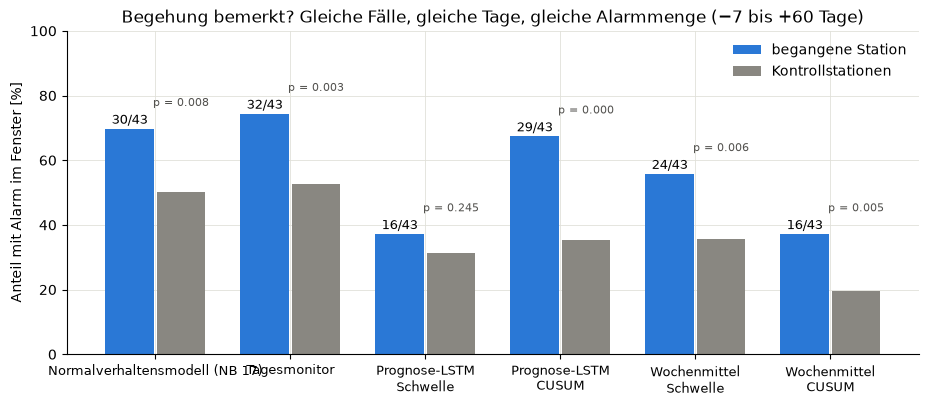

,nur Normalverhaltensmodell,nur Kandidat,beide,keiner,p (McNemar)
Tagesmonitor,0.0,2.0,30.0,11.0,0.500
"Prognose-LSTM, Schwelle",15.0,1.0,15.0,12.0,0.001
"Prognose-LSTM, CUSUM",7.0,6.0,23.0,7.0,1.000
"Wochenmittel, Schwelle",11.0,5.0,19.0,8.0,0.210
"Wochenmittel, CUSUM",16.0,2.0,14.0,11.0,0.001


In [6]:
lange = alarm_tab[alarm_tab["Fenster"] == "−7 bis +60 Tage"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(lange))
ax.bar(x - 0.19, lange["Quote"] * 100, 0.36, color=FARBE["blau"], label="begangene Station")
ax.bar(x + 0.19, lange["Kontrollquote"] * 100, 0.36, color=FARBE["grau"], label="Kontrollstationen")
for xi, zeile in lange.iterrows():
    ax.text(xi - 0.19, zeile["Quote"] * 100 + 1.5, f"{zeile['Treffer']}/{zeile['Fälle']}", ha="center", fontsize=9)
    ax.text(xi + 0.19, max(zeile["Quote"], zeile["Kontrollquote"]) * 100 + 7, f"p = {zeile['p (einseitig)']:.3f}",
            ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, lange["Kandidat"].str.replace(", ", "\n"), fontsize=9)
ax.set_ylabel("Anteil mit Alarm im Fenster [%]")
ax.set_ylim(0, 100)
ax.set_title("Begehung bemerkt? Gleiche Fälle, gleiche Tage, gleiche Alarmmenge (−7 bis +60 Tage)")
ax.legend(frameon=False, loc="upper right")
plt.show()

bezug = treffer_je_fall[("Normalverhaltensmodell (NB 17)", 60)]
paarweise = pd.DataFrame({name: ps.mcnemar(bezug, treffer_je_fall[(name, 60)].reindex(bezug.index))
                          for name in kandidaten_a if not name.startswith("Normal")}).T
paarweise.rename(columns={"nur A": "nur Normalverhaltensmodell", "nur B": "nur Kandidat"}).round(3)

- Bild: Trefferquote an begangenen Stationen (blau) neben Kontrollstationen (grau). Entscheidend ist der Abstand, nicht die Höhe.
- Tabelle: jeder Kandidat Fall für Fall gegen das Normalverhaltensmodell. Der McNemar-Test schaut nur auf die Fälle, in denen genau einer alarmiert.

**Ergebnis**

Grundlage: 79 Stationen, 15.142 Heiztage (01.06.2024 bis 09.06.2025), 43 Begehungen, Budget 204 Alarme.

| Kandidat | Parameter | bemerkt (−7 bis +60) | Kontrolle | Hebel | p | in 14 Tagen | p |
|---|---|---|---|---|---|---|---|
| Tagesmonitor | h = 4,5 | **33/43 (77 %)** | 53 % | 1,45 | **0,001** | 18/39 (46 %) gegen 24 % | **0,003** |
| Normalverhaltensmodell (Notebook 18) | h = 5 | 30/43 (70 %) | 50 % | 1,39 | 0,008 | 14/39 (36 %) gegen 22 % | 0,033 |
| Prognose-LSTM, CUSUM | h = 8 | 24/43 (56 %) | 40 % | 1,42 | 0,022 | 8/39 (21 %) gegen 14 % | 0,15 |
| Wochenmittel, Schwelle | z ≥ 3 | 24/43 (56 %) | 36 % | 1,56 | 0,006 | 14/39 (36 %) gegen 17 % | 0,003 |
| Wochenmittel, CUSUM | h = 12 | 16/43 (37 %) | 20 % | 1,91 | 0,005 | 7/39 (18 %) gegen 11 % | 0,13 |
| Prognose-LSTM, Schwelle | z ≥ 3,5 | 16/43 (37 %) | 32 % | 1,18 | 0,26 | 7/39 (18 %) gegen 17 % | 0,52 |

- Die Kennlinie gegen die Außentemperatur bleibt der beste Wächter. Tagesmonitor und Normalverhaltensmodell sind Fall für Fall nicht unterscheidbar (3 Fälle mehr, keiner weniger, McNemar p = 0,25). Für den Betrieb gilt der Tagesmonitor, weil er als Paket auf neuen Daten läuft.
- Die Vermutung aus Notebook 30 stimmt zur Hälfte: Dieselben LSTM-z-Werte mit CUSUM bemerken 24 statt 16 Begehungen (p = 0,022). Zur Kennlinie fehlen weiter 6 bis 9 Fälle. Passt dazu, dass das LSTM die letzten 7 Tage als Eingang nimmt und eine bleibende Veränderung nach einer Woche „normal“ wird.
- Ohne Lernen geht es besser als mit dem LSTM-Wächter aus Notebook 28: Wochenmittel mit Schwelle bemerkt 24 Begehungen, auch schon in 14 Tagen (p = 0,003).
- Fall für Fall liegt das Normalverhaltensmodell nur gegen „LSTM, Schwelle“ und „Wochenmittel, CUSUM“ belegt vorn (je p = 0,001).

### 3.2 Weitere Wächter aus dem Projekt

Dieselbe Prüfung für alle übrigen Ansätze, die je Station und Tag einen Alarm liefern können.

| Kandidat | Notebook | Erwartung | Alarmregel |
|---|---|---|---|
| Kennlinienmonitor | 13 | Kennlinie log V über log P im rollierenden Fenster | Sprungscore in Steigung oder Residuum über Schwelle |
| Tagesmonitor ohne Netzereignisse | 24 | wie Tagesmonitor | CUSUM; Verschlechterungen an Netzereignistagen gestrichen |
| ARIMA-Wächter | 06 | Tagesrücklauf aus Außentemperatur mit AR(1)-Fehlern, gelernt im ersten Jahr | Ein-Schritt-Fehler; Schwelle an zwei Tagen oder CUSUM |
| Netzresiduum, stationseigenes Residuum, Isolation Forest, Kurzschluss-Zustand, Dynamik | 16 (mit Stundenclustern aus 09) | Rücklauf gegen Netz oder eigene Erwartung, Ausreißer, Zeitanteil im Kurzschlusszustand, Rücklaufdynamik | Alarm am ersten Tag einer persistent auffälligen Phase (mindestens 7 von 14 Tagen) |

- Alle laufen auf denselben Tagen und Fällen und, wo möglich, mit demselben Alarmbudget.
- Notebook 16 lernt seine Erwartung auf der ganzen Zeit, auch auf den Prüftagen. Das ist ein Vorteil für Notebook 16.

In [7]:
from src import alarmbewertung as ab
from src import anomalie as an
from src import clustervalidierung as cvl
from src import kennlinien_monitor as km
from src import nb00_daten as nb00
from src import netzereignisse as ne
from src import tagespanel as tp
from src import weather
from src import zeitreihenmodell as zr
from sklearn.preprocessing import StandardScaler

#Kennlinien-Strang: Netzvergleich und Kennlinienmonitor (einmal, auch für Teil B)
sb_e = sbl.eingaben()
netz = sbl.rechne(sb_e["serien"], sb_e["termine"], sb_e["anschlusswerte"], sb_e["bhkw"], sb_e["ohne_datum"])
mon = netz["monitor"]


def kennlinienmonitor_alarme(schwelle):
    teile = []
    for frame, spalte in ((mon["fenster"], "score_steigung"), (mon["residuum"], "score_residuum")):
        for m, t in frame.groupby("meter"):
            a = km.alarme(t["datum"], t[spalte], schwelle=schwelle)
            if len(a):
                teile.append(pd.DataFrame({"zaehler": int(m), "datum": pd.to_datetime(a["datum"])}))
    return pd.concat(teile, ignore_index=True) if teile else pd.DataFrame(columns=["zaehler", "datum"])


def tagesmonitor_ohne_netzereignis(h):
    zeilen = []
    for (m, kanal), g in normal["verlauf"].groupby(["meter", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [{"meter": m, "kanal": kanal, "datum": g["datum"].iloc[i], "richtung": r,
                    "beginn": g["datum"].iloc[s]} for i, r, s in al]
    einsatz = ne.einsaetze(pd.DataFrame(zeilen))
    beob = tm.beobachtete_tage(normal["verlauf"])
    tage = ne.netztage(einsatz[einsatz["bewertung"] == "schlechter"], beob, fenster=ne.FENSTER_TAGE, seed=0)["tage"]
    markiert_ne = ne.markiere(einsatz, tage.loc[tage["netzereignis"], "datum"], [], fenster=ne.FENSTER_TAGE)
    ohne = markiert_ne[~(markiert_ne["netzereignis"] & (markiert_ne["bewertung"] == "schlechter"))]
    return ohne.rename(columns={"meter": "zaehler"})[["zaehler", "datum"]]


print(f"Kennlinienmonitor: {mon['fenster']['meter'].nunique()} Stationen im Parameterkanal, "
      f"{mon['residuum']['meter'].nunique()} im Residuenkanal")

Kennlinienmonitor: 92 Stationen im Parameterkanal, 92 im Residuenkanal


- Rechnet den Kennlinien-Strang einmal (`stationsblatt.rechne`). Daraus kommen der Kennlinienmonitor (Notebook 13) und in Teil B Netzvergleich, Potenzial und Vergleichsgruppen.
- `kennlinienmonitor_alarme` baut die Alarme beider Kanäle für eine beliebige Schwelle.
- `tagesmonitor_ohne_netzereignis` setzt den Vorschlag aus Notebook 24 um: Verschlechterungen, die an einem Netzereignistag beginnen, zählen nicht als Hausfehler.

In [8]:
#ARIMA-Wächter: Tagesrücklauf ~ Außentemperatur mit AR(1)-Fehlern (NB 06)
serien_nb00 = nb00.lade_serien(PROCESSED / "real_meters")
von = min(d.index[0] for d in serien_nb00.values() if len(d))
bis = max(d.index[-1] for d in serien_nb00.values() if len(d))
t_aussen = weather.load_outdoor_temperature(von, bis, allow_download=False)
ARX = zr.ModellSpec("arx_100", p=1, d=0, exog=("t_out",))
stuecke = []
for m in sorted(serien_nb00):
    fr = zr.tagesreihe(serien_nb00[m], t_aussen)
    gueltig = fr.index[fr["y"].notna()]
    if len(gueltig) < 60:
        continue
    r0 = gueltig[0]
    r1 = r0 + pd.Timedelta(days=365)
    spaeter = [pd.Timestamp(t) for t in termine.get(int(m), []) if pd.Timestamp(t) > r0]
    if spaeter and min(spaeter) - pd.Timedelta(days=14) < r1:
        r1 = min(spaeter) - pd.Timedelta(days=14)
    lern = fr[(fr.index >= r0) & (fr.index < r1)]
    if lern["y"].notna().sum() < 60:
        continue
    anp = zr.fit(lern, ARX)
    if not anp.ok:
        continue
    u = fr["y"].to_numpy() - (anp.beta[0] + anp.beta[1] * fr["t_out"].to_numpy())
    fehler = pd.Series(u - anp.phi[0] * np.r_[np.nan, u[:-1]], index=fr.index)     #Ein-Schritt-Fehler
    ref = fehler[(fehler.index >= r0) & (fehler.index < r1)].dropna()
    s = max(1.4826 * float(np.median(np.abs(ref - ref.median()))), 0.1)
    t = pd.DataFrame({"zaehler": int(m), "tag": fr.index, "z_rl": (fehler / s).to_numpy(), "z_fluss": 0.0})
    stuecke.append(t[(t["tag"] >= r1) & t["z_rl"].notna()])
arima = pd.concat(stuecke, ignore_index=True).sort_values(["zaehler", "tag"]).reset_index(drop=True)
arima_kal = pd.DataFrame({"phi_rl": 0.0, "phi_fluss": 0.0}, index=sorted(arima["zaehler"].unique()))
print(f"ARIMA-Wächter: {arima['zaehler'].nunique()} Stationen, {len(arima):,} überwachte Heiztage")

#NB 16: Tagespanel mit Stundenclustern und fünf Detektoren
panel_h, _ = cvl.lade_stundenpanel(PROCESSED / "real_meters")
panel_h = cvl.mit_kontext(panel_h, t_aussen)
panel_h["cluster"] = cvl.fit_minibatch_kmeans(StandardScaler().fit_transform(panel_h[cvl.BETRIEBS_FEATURES]), 5, n_init=10)
profil_h = cvl.zentroid_profil(panel_h[cvl.BETRIEBS_FEATURES].to_numpy(), panel_h["cluster"].to_numpy(), cvl.BETRIEBS_FEATURES)
KURZ = int(profil_h[profil_h["flow_norm"] > 0.3]["dt"].idxmin())
ANTEIL = f"anteil_c{KURZ}"
panel = tp.baue_tagespanel(serien_nb00, stundencluster=panel_h, t_out=t_aussen)
panel, _ = an.erwartungsmodell_netz(panel)
panel, _ = an.erwartungsmodell_station(panel)
panel, _ = an.score_isolation_forest(panel, ["rt_median", "dt_mean_loaded", "t_out_tag", "last_anteil", "power_mean",
                                             "flow_median", "rt_d1_abs_mean", "rt_vl_kopplung"])
panel = an.score_zustand(panel, [ANTEIL])
panel, _ = an.score_dynamik(panel)
NB10 = {f"score_{an.D_RESID_NETZ}": "NB 10: Netzresiduum", f"score_{an.D_RESID_STATION}": "NB 10: stationseigenes Residuum",
        f"score_{an.D_IFOREST}": "NB 10: Isolation Forest", f"score_{an.D_ZUSTAND}": "NB 10: Kurzschluss-Zustand",
        f"score_{an.D_DYNAMIK}": "NB 10: Dynamik"}


def nb10_alarme(spalte):
    def f(quantil):
        p2, _ = an.persistente_tage(panel, spalte, quantil=quantil)
        t = (p2[["meter", "datum", f"persistent_{spalte}"]]
             .rename(columns={"meter": "zaehler", "datum": "tag", f"persistent_{spalte}": "w"})
             .sort_values(["zaehler", "tag"]).reset_index(drop=True))
        a = pw.alarme_aus_warnungen(t, t["w"].astype(bool))
        return t.loc[a, ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


print(f"Tagespanel {panel.shape}, Kurzschlussverdacht ist Stundencluster {KURZ}")

ARIMA-Wächter: 82 Stationen, 17,344 überwachte Heiztage


Tagespanel (85986, 50), Kurzschlussverdacht ist Stundencluster 1


- ARIMA-Wächter: Notebook 06 fand als bestes Modell für den Tagesrücklauf „Außentemperatur mit AR(1)-Fehlern“, prüfte aber nur Fenster um Begehungen. Hier wird daraus ein Wächter: je Station im ersten Jahr gelernt (spätestens 14 Tage vor der ersten Begehung), danach der Ein-Schritt-Fehler in Streuungen des Lernjahres, mit denselben Alarmregeln wie beim LSTM.
- Notebook 16: baut dessen Tagespanel mit den Stundenclustern und den fünf Detektoren nach. Alarm ist der erste Tag einer persistent auffälligen Phase nach mindestens sieben ruhigen Tagen.

In [9]:
suche_weitere = {
    "Kennlinienmonitor (NB 14)": (kennlinienmonitor_alarme, [2, 2.5, 3, 3.5, 4, 5, 6]),
    "Tagesmonitor ohne Netzereignisse (NB 24)": (tagesmonitor_ohne_netzereignis, [3, 3.5, 4, 4.5, 5]),
    "ARIMA-Wächter, Schwelle": (schwellen_alarme(arima), [1.5, 2, 2.5, 3, 3.5, 4]),
    "ARIMA-Wächter, CUSUM": (cusum_alarme(arima, arima_kal), [1.5, 2, 3, 4, 5, 6, 8]),
    **{name: (nb10_alarme(spalte), [0.5, 0.6, 0.7, 0.8, 0.9]) for spalte, name in NB10.items()},
}
zeilen, eigene_tage = [], {"Normalverhaltensmodell (NB 17)": seb_beob, "Tagesmonitor": tm_beob}
for name, (funktion, werte) in suche_weitere.items():
    wert, tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    alarme = funktion(wert)
    kandidaten_a[name] = alarme
    a = ps.auf_tagen(alarme, gemeinsam)
    for nach in (60, 14):
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), "Parameter": wert,
                       "Budget erreichbar": bool(tafel["alarme"].max() >= 0.9 * budget), **ps.bilanz(t, name)})
eigene_tage["ARIMA-Wächter, Schwelle"] = eigene_tage["ARIMA-Wächter, CUSUM"] = arima[["zaehler", "tag"]].rename(columns={"tag": "datum"})
eigene_tage["Kennlinienmonitor (NB 14)"] = mon["residuum"][["meter", "datum"]].rename(columns={"meter": "zaehler"})
eigene_tage["Tagesmonitor ohne Netzereignisse (NB 24)"] = tm_beob
for name in NB10.values():
    eigene_tage[name] = panel[["meter", "datum"]].rename(columns={"meter": "zaehler"})
weitere_a = pd.DataFrame(zeilen)
paarweise_weitere = pd.DataFrame({name: ps.mcnemar(bezug, treffer_je_fall[(name, 60)].reindex(bezug.index).fillna(False))
                                  for name in suche_weitere}).T
alle_a = pd.concat([alarm_tab.assign(Parameter=np.nan, **{"Budget erreichbar": True}), weitere_a], ignore_index=True)
for _, g in alle_a.groupby("Fenster"):
    alle_a.loc[g.index, "p (Holm)"] = ps.holm(g["p (einseitig)"])     #über alle Wächter eines Fensters
display(alle_a[alle_a["Fenster"] == "−7 bis +60 Tage"].sort_values("p (einseitig)")
        [["Kandidat", "Parameter", "Alarme", "Budget erreichbar", "Fälle", "Treffer", "Quote", "Kontrollquote", "Hebel", "p (einseitig)", "p (Holm)"]].round(3))
display(alle_a[alle_a["Fenster"] == "−7 bis +14 Tage"].sort_values("p (einseitig)")
        [["Kandidat", "Treffer", "Fälle", "Quote", "Kontrollquote", "Hebel", "p (einseitig)", "p (Holm)"]].round(3))
paarweise_weitere.rename(columns={"nur A": "nur Normalverhaltensmodell", "nur B": "nur Kandidat"}).round(3)

,Kandidat,Parameter,Alarme,Budget erreichbar,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig),p (Holm)
3,"Prognose-LSTM, CUSUM",NaN,198,True,43,29,0.674,0.354,1.907,0.000,0.000
1,Tagesmonitor,NaN,207,True,43,32,0.744,0.525,1.417,0.003,0.038
14,Tagesmonitor ohne Netzereignisse (NB 24),4.5,207,True,43,32,0.744,0.525,1.417,0.003,0.038
5,"Wochenmittel, CUSUM",NaN,182,True,43,16,0.372,0.195,1.904,0.005,0.064
4,"Wochenmittel, Schwelle",NaN,216,True,43,24,0.558,0.357,1.563,0.006,0.064
0,Normalverhaltensmodell (NB 17),NaN,202,True,43,30,0.698,0.503,1.387,0.008,0.076
16,"ARIMA-Wächter, Schwelle",2.0,182,True,43,22,0.512,0.342,1.496,0.016,0.146
28,NB 10: Dynamik,0.5,86,False,43,11,0.256,0.160,1.599,0.072,0.575
12,Kennlinienmonitor (NB 14),3.5,187,True,43,28,0.651,0.534,1.220,0.081,0.575
18,"ARIMA-Wächter, CUSUM",4.0,202,True,43,20,0.465,0.397,1.172,0.222,1.000


,Kandidat,Treffer,Fälle,Quote,Kontrollquote,Hebel,p (einseitig),p (Holm)
10,"Wochenmittel, Schwelle",14,39,0.359,0.165,2.170,0.003,0.041
7,Tagesmonitor,17,39,0.436,0.253,1.723,0.010,0.137
15,Tagesmonitor ohne Netzereignisse (NB 24),17,39,0.436,0.253,1.723,0.010,0.137
17,"ARIMA-Wächter, Schwelle",9,39,0.231,0.101,2.281,0.014,0.169
19,"ARIMA-Wächter, CUSUM",11,39,0.282,0.143,1.966,0.018,0.203
6,Normalverhaltensmodell (NB 17),14,39,0.359,0.220,1.635,0.033,0.330
27,NB 10: Kurzschluss-Zustand,4,39,0.103,0.034,2.978,0.044,0.400
29,NB 10: Dynamik,4,39,0.103,0.035,2.949,0.046,0.400
9,"Prognose-LSTM, CUSUM",10,39,0.256,0.164,1.566,0.094,0.656
23,NB 10: stationseigenes Residuum,8,39,0.205,0.127,1.621,0.112,0.672


,nur Normalverhaltensmodell,nur Kandidat,beide,keiner,p (McNemar)
Kennlinienmonitor (NB 14),8.0,6.0,22.0,7.0,0.791
Tagesmonitor ohne Netzereignisse (NB 24),0.0,2.0,30.0,11.0,0.500
"ARIMA-Wächter, Schwelle",14.0,6.0,16.0,7.0,0.115
"ARIMA-Wächter, CUSUM",14.0,4.0,16.0,9.0,0.031
NB 10: Netzresiduum,25.0,1.0,5.0,12.0,0.000
NB 10: stationseigenes Residuum,17.0,5.0,13.0,8.0,0.017
NB 10: Isolation Forest,20.0,4.0,10.0,9.0,0.002
NB 10: Kurzschluss-Zustand,23.0,3.0,7.0,10.0,0.000
NB 10: Dynamik,25.0,6.0,5.0,7.0,0.001


- Wählt je Kandidat den Parameter nahe am Budget und prüft mit derselben `trefferpruefung`.
- `Budget erreichbar` = falsch, wenn der Kandidat selbst beim lockersten Parameter deutlich weniger Alarme gibt (Notebook 16 fasst viele Tage zu einem Alarm zusammen). Der Hebel bleibt vergleichbar.
- Drei Tabellen: alle Wächter nach p sortiert, das 14-Tage-Fenster, Fall für Fall gegen das Normalverhaltensmodell.
- p (Holm) korrigiert für die vielen Tests: Bei 15 Kandidaten ist ein einzelnes p unter 0,05 auch zufällig wahrscheinlich.

**Ergebnis**

Alle 15 Wächter auf denselben 43 Begehungen, nach p sortiert, Holm über alle 15:

| Wächter | Notebook | bemerkt (−7 bis +60) | Kontrolle | Hebel | p | p (Holm) |
|---|---|---|---|---|---|---|
| Tagesmonitor (Kennlinie + CUSUM) | 20 | **33/43** | 53 % | 1,45 | 0,001 | **0,017** |
| Tagesmonitor ohne Netzereignisse | 24 | 33/43 | 53 % | 1,45 | 0,001 | 0,017 |
| Wochenmittel + CUSUM | – | 16/43 | 20 % | 1,91 | 0,005 | 0,07 |
| Wochenmittel + Schwelle | – | 24/43 | 36 % | 1,56 | 0,006 | 0,07 |
| Normalverhaltensmodell | 18 | 30/43 | 50 % | 1,39 | 0,008 | 0,08 |
| ARIMA-Wächter + Schwelle | 06 | 22/43 | 34 % | 1,50 | 0,016 | 0,16 |
| Prognose-LSTM + CUSUM | 28 | 24/43 | 40 % | 1,42 | 0,022 | 0,20 |
| Dynamik | 16 | 11/43 | 16 % | 1,60 | 0,07 | 0,57 |
| Kennlinienmonitor | 13 | 27/43 | 53 % | 1,18 | 0,14 | 0,94 |
| ARIMA-Wächter + CUSUM | 06 | 20/43 | 40 % | 1,17 | 0,22 | 1 |
| Prognose-LSTM + Schwelle | 28 | 16/43 | 32 % | 1,18 | 0,26 | 1 |
| Kurzschluss-Zustand, stationseigenes Residuum, Isolation Forest, Netzresiduum | 16 | 6 bis 18 | – | 0,52 bis 0,98 | ≥ 0,58 | 1 |

- Nach Holm bleibt nur die Kennlinie mit CUSUM belegt (Tagesmonitor). Im 14-Tage-Fenster kommt das Wochenmittel mit Schwelle dazu (je p = 0,038 nach Holm).
- Der Netzereignis-Filter (Notebook 24) ändert nichts: Das einzige Netzereignis mit Verschlechterungen liegt im Dezember 2022, vor dem Prüfzeitraum.
- ARIMA liegt mit 22 von 43 zwischen LSTM und Kennlinie; Notebook 06 sah dasselbe Signal (38 % gegen 18 % Placebo).
- Der Kennlinienmonitor (Notebook 13) trifft viel, die Kontrollen aber genauso (Hebel 1,18). Das erklärt, warum ihn der Tagesmonitor ersetzt hat.
- Die Detektoren aus Notebook 16 taugen nicht als Alarm: Fall für Fall verliert jeder deutlich (McNemar p ≤ 0,017), das Netzresiduum liegt unter Zufall. Sie erreichen das Budget nicht (höchstens 166 statt 204). Gebaut sind sie als Rangliste je Station; so laufen sie in Teil B mit.

### 3.3 Eingerechnete Fehler: plötzliche Störungen

- Begehungen verschieben den Betrieb nur wenig (Notebook 30: im Median um eine halbe Streuung). Ein Wächter soll aber auch plötzliche Fehler finden.
- Wie in Notebook 28 werden Fehler in echte Stundenwerte der sauberen Testzeit (Sommer 2024) geschrieben: je Station bis zu drei Fenster von 8 Tagen, gleiche Fenster für alle.
- Schwellenregel: Warnung bei |z| ≥ Schwelle an zwei Tagen hintereinander. CUSUM: Konten starten am ersten Fenstertag bei null.
- Fair verglichen bei gleicher Fehlalarmquote: höchstens 10 % Fehlalarme in Fenstern ohne Fehler. Das Normalverhaltensmodell rechnet aus Zählerständen und fehlt hier.

In [10]:
FENSTER = 8
FEHLER = ["ohne", "Bypass 50", "Bypass 150", "Fühler hängt", "Sollwert +5 K"]
z_lern = pw.z_werte(r["abweichungen"], r["kalibrierung"], r["faktor"])
test = z_lern[(z_lern["abschnitt"] == "Test (Sommer 2024)") & z_lern["zaehler"].isin(r["kalibrierung"].index)]
rng = np.random.default_rng(pw.SEED)
starts = []
for zaehler, g in test.groupby("zaehler"):
    moeglich = [i for k, i in enumerate(g.index[:-FENSTER + 1]) if (g["tag"].iloc[k + FENSTER - 1] - g["tag"].iloc[k]).days == FENSTER - 1]
    starts += list(rng.choice(moeglich, size=min(3, len(moeglich)), replace=False)) if moeglich else []
fenster = np.array([np.arange(s, s + FENSTER) for s in starts])
test_idx = test.index.to_numpy()
print(f"{len(fenster)} Testfenster an {test.loc[starts, 'zaehler'].nunique()} Stationen (gleiche Ziehung wie NB 21)")


def z_mit_fehler(fehler, erwartung):
    feld = ps.einrechnen(r["werte"], fenster, fehler)
    if erwartung == "lstm":
        x = pw.skalieren(feld, r["tage"], r["skalierung"])
        rl, fl = pw.vorhersagen(r["modell"], x, r["tage"], test_idx, r["skalierung"])
        kal, fak = r["kalibrierung"], r["faktor"]
    else:
        rl, fl = pw.wochenmittel(feld, test_idx)
        kal, fak = kal_w, faktor_w
    return pw.z_werte(pw.abweichungen(feld, r["tage"], test_idx, rl, fl), kal, fak), kal


def fensterweise(z, kal, schwellen, grenzen):
    ergebnis = []
    for f in fenster:
        zr, zf = z["z_rl"].reindex(f).to_numpy(), z["z_fluss"].reindex(f).to_numpy()
        station = int(z.loc[f[0], "zaehler"])
        zeile = {}
        for s in schwellen:
            auff = (np.abs(zr) >= s) | (np.abs(zf) >= s)
            zeile[("Schwelle", s)] = bool((auff[1:] & auff[:-1]).any())
        for h in grenzen:
            alarm = False
            for werte_z, phi in ((zr, kal.at[station, "phi_rl"]), (zf, kal.at[station, "phi_fluss"])):
                zz = werte_z / np.sqrt((1 + phi) / (1 - phi))
                alarm |= bool(tm.cusum(zz[np.isfinite(zz)], h=h, deckel=max(tm.CUSUM_MAX, 2 * h))[2])
            zeile[("CUSUM", h)] = alarm
        ergebnis.append(zeile)
    return pd.DataFrame(ergebnis).mean()


SCHWELLEN_INJ = [3, 3.5, 4, 5, 6, 7, 8]
GRENZEN_INJ = [6, 8, 10, 12, 15, 20, 25]
injektion = {}
for erwartung in ("lstm", "wochenmittel"):
    for fehler in FEHLER:
        z, kal = z_mit_fehler(fehler, erwartung)
        injektion[(erwartung, fehler)] = fensterweise(z, kal, SCHWELLEN_INJ, GRENZEN_INJ)
zeilen = [{"Erwartung": erwartung, "Regel": regel, "Parameter": par, "Fehler": fehler, "Anteil": wert}
          for (erwartung, fehler), anteile in injektion.items() for (regel, par), wert in anteile.items()]
inj = pd.DataFrame(zeilen).pivot_table(index=["Erwartung", "Regel", "Parameter"], columns="Fehler", values="Anteil")[FEHLER]
print("Kontrolle: LSTM mit Schwelle 4 wie NB 21 (84 % Bypass 150, 55 % Bypass 50, 43 % Fühler, 19 % Sollwert, 8 % Fehlalarm):")
inj.loc[("lstm", "Schwelle", 4)].round(2)

240 Testfenster an 80 Stationen (gleiche Ziehung wie NB 21)


Kontrolle: LSTM mit Schwelle 4 wie NB 21 (84 % Bypass 150, 55 % Bypass 50, 43 % Fühler, 19 % Sollwert, 8 % Fehlalarm):


Fehler
ohne             0.11
Bypass 50        0.52
Bypass 150       0.85
Fühler hängt     0.43
Sollwert +5 K    0.21
Name: (lstm, Schwelle, 4.0), dtype: float64

- Zieht die Testfenster wie Notebook 28 (gleicher Zufallsstartwert) und schreibt die Fehler mit `ps.einrechnen` in eine Kopie der Stundenwerte.
- Rechnet die z-Werte je Fehler neu, mit LSTM und mit Wochenmittel als Erwartung, und prüft beide Alarmregeln mit mehreren Parametern.
- Kontrolle: LSTM mit Schwelle z ≥ 4 ergibt die Zahlen aus Notebook 28.

,Erwartung,Regel,Parameter,Fehlalarm,Bypass 50,Bypass 150,Fühler hängt,Sollwert +5 K
0,Prognose-LSTM,CUSUM,20.0,0.06,0.40,0.80,0.33,0.17
1,Prognose-LSTM,Schwelle,5.0,0.08,0.35,0.76,0.33,0.16
2,Wochenmittel,CUSUM,20.0,0.07,0.43,0.77,0.18,0.15
3,Wochenmittel,Schwelle,7.0,0.08,0.40,0.78,0.17,0.16


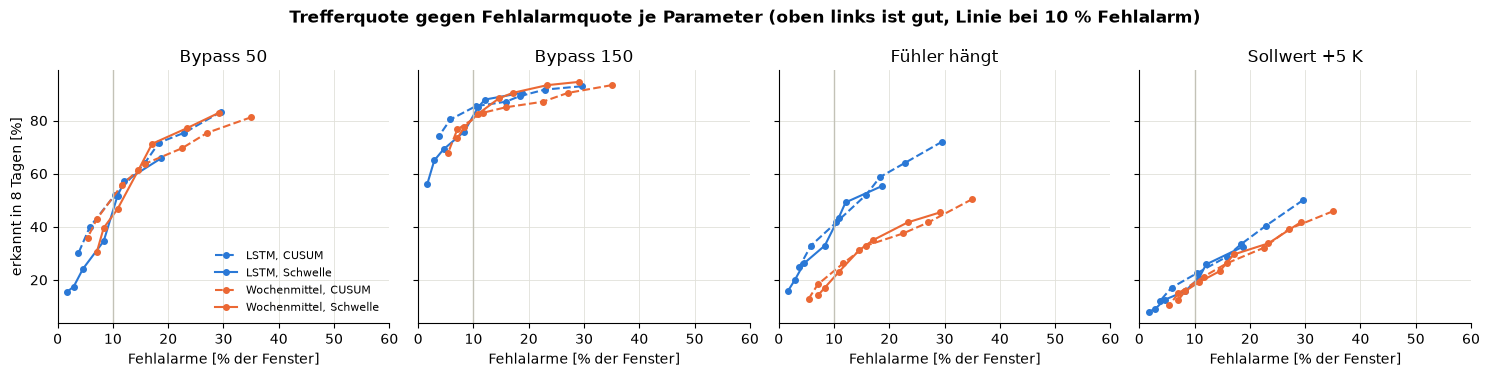

In [11]:
def beste_bei_fehlalarm(tafel, grenze=0.10):
    zeilen = []
    for (erwartung, regel), g in tafel.groupby(level=[0, 1]):
        ok = g[g["ohne"] <= grenze]
        wahl = ok.iloc[0] if len(ok) else g.sort_values("ohne").iloc[0]     #kleinster Parameter mit ≤ 10 %
        zeilen.append({"Erwartung": "Prognose-LSTM" if erwartung == "lstm" else "Wochenmittel", "Regel": regel,
                       "Parameter": wahl.name[2], **wahl.to_dict()})
    return pd.DataFrame(zeilen).rename(columns={"ohne": "Fehlalarm"})

inj_vergleich = beste_bei_fehlalarm(inj)
display(inj_vergleich.round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
stil = {("lstm", "Schwelle"): (FARBE["blau"], "-"), ("lstm", "CUSUM"): (FARBE["blau"], "--"),
        ("wochenmittel", "Schwelle"): (FARBE["orange"], "-"), ("wochenmittel", "CUSUM"): (FARBE["orange"], "--")}
for ax, fehler in zip(axes, FEHLER[1:]):
    for (erwartung, regel), g in inj.groupby(level=[0, 1]):
        farbe, linie = stil[(erwartung, regel)]
        name = ("LSTM" if erwartung == "lstm" else "Wochenmittel") + f", {regel}"
        ax.plot(g["ohne"] * 100, g[fehler] * 100, linie, marker="o", ms=4, lw=1.5, color=farbe, label=name)
    ax.axvline(10, color="#c3c2b7", lw=1)
    ax.set_title(fehler)
    ax.set_xlabel("Fehlalarme [% der Fenster]")
    ax.set_xlim(0, 60)
axes[0].set_ylabel("erkannt in 8 Tagen [%]")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Trefferquote gegen Fehlalarmquote je Parameter (oben links ist gut, Linie bei 10 % Fehlalarm)", fontweight="bold")
fig.tight_layout()
plt.show()

- Wählt je Erwartung und Regel den Parameter mit höchstens 10 % Fehlalarmen und zeigt dort die Trefferquoten.
- Bild: jede Linie ein Kandidat, jeder Punkt ein Parameter. Höher bei gleicher Fehlalarmquote ist besser.

**Ergebnis**

Die Kontrolle stimmt (Zahlen wie Notebook 28). Bei höchstens 10 % Fehlalarmen in 8 Tagen:

| Erwartung | Regel | Fehlalarm | Bypass 50 l/h | Bypass 150 l/h | Fühler hängt | Sollwert +5 K |
|---|---|---|---|---|---|---|
| **Prognose-LSTM** | **Schwelle z ≥ 4** | 8 % | **55 %** | **84 %** | **43 %** | **19 %** |
| Prognose-LSTM | CUSUM h = 20 | 6 % | 48 % | 81 % | 36 % | 17 % |
| Wochenmittel | Schwelle z ≥ 7 | 8 % | 40 % | 78 % | 17 % | 16 % |
| Wochenmittel | CUSUM h = 20 | 7 % | 43 % | 77 % | 18 % | 15 % |

- Für plötzliche Fehler ist das LSTM der beste Wächter: hängender Fühler 43 % gegen 17 %, kleiner Bypass 55 % gegen 40 %.
- Hier passt die Schwellenregel: Ein plötzlicher Fehler ist ein großer Sprung. CUSUM braucht für dieselbe Fehlalarmquote eine hohe Grenze und ist dann langsamer.
- Ein verstellter Sollwert (+5 K) bleibt für alle schwer (15 bis 19 %). Dafür ist die Kennlinie mit CUSUM da.

In [12]:
FALL, DATUM = 68956351, pd.Timestamp("2024-09-09")
ventilfall = []
for name, alarme in kandidaten_a.items():
    tage_bis = ps.erster_alarm_nach(alarme, FALL, DATUM, bis_tage=60)
    ventilfall.append({"Kandidat": name, "erster Alarm nach der Begehung [Tage]": tage_bis if tage_bis is not None else "keiner in 60 Tagen"})

last = []
for name, alarme in kandidaten_a.items():
    eigene = eigene_tage.get(name, lstm_beob)
    eigene = eigene[pd.to_datetime(eigene["datum"]) >= AB]
    a = alarme[pd.to_datetime(alarme["datum"]) >= AB]
    a = ps.auf_tagen(a, eigene)
    last.append({"Kandidat": name, "Alarme je Station und Jahr": ps.alarme_je_jahr(a, eigene)})
pd.DataFrame(ventilfall).merge(pd.DataFrame(last), on="Kandidat").round(1)

,Kandidat,erster Alarm nach der Begehung [Tage],Alarme je Station und Jahr
0,Normalverhaltensmodell (NB 17),2,3.5
1,Tagesmonitor,2,3.7
2,"Prognose-LSTM, Schwelle",7,4.5
3,"Prognose-LSTM, CUSUM",4,4.4
4,"Wochenmittel, Schwelle",1,5.7
5,"Wochenmittel, CUSUM",1,4.9
6,Kennlinienmonitor (NB 14),3,4.8
7,Tagesmonitor ohne Netzereignisse (NB 24),2,3.7
8,"ARIMA-Wächter, Schwelle",27,5.2
9,"ARIMA-Wächter, CUSUM",26,5.2


### 3.4 Ventilfall 68956351 und Alarmlast

- Ventilfall: Das Ventil stand rund drei Jahre offen und wurde am 09.09.2024 getauscht. Nach wie vielen Tagen meldet jeder Kandidat die Veränderung?
- Alarmlast: Alarme je Station und Jahr ab Juni 2024, jeder Kandidat auf seinen eigenen Tagen (das LSTM auch im Sommer). So viel käme im Betrieb an.

**Ergebnis**

- Ventilfall: Normalverhaltensmodell und Tagesmonitor nach 2 Tagen, Wochenmittel nach 1, Kennlinienmonitor nach 3, LSTM mit CUSUM nach 4 und mit Schwelle nach 7, Dynamik (Notebook 16) nach 6 Tagen. ARIMA braucht 26 bis 27 Tage, die übrigen Detektoren aus Notebook 16 melden nichts in 60 Tagen.
- Alarmlast: Kennlinie und LSTM 3,5 bis 3,8 Alarme je Station und Jahr (LSTM auch im Sommer). Wochenmittel, Kennlinienmonitor und ARIMA alarmieren mit 4,8 bis 5,7 öfter.

**Fazit Alarm:** zwei Wächter für verschiedene Aufgaben
- Tagesmonitor (Kennlinie + CUSUM) für schleichende, bleibende Veränderungen im Heizbetrieb, belegt an echten Begehungen. Hauptkanal; seine Verschlechterungsalarme ordnen innerhalb einer Dringlichkeitsstufe (Abschnitt 6.1).
- Prognose-LSTM (Schwelle z ≥ 4) für plötzliche große Fehler, auch im Sommer, belegt nur an eingerechneten Fehlern. Seine Alarme sind ein Hinweis, bis sie an echten Fällen bestätigt sind.

## 4 Teil B: Fehler erkennen – welche Stationen haben einen Dauerfehler?

- Ein Wächter vergleicht jede Station mit sich selbst. Eine Station, die von Anfang an schlecht läuft, findet er nie. Dafür braucht es einen Vergleich über die Stationen.
- Prüfbasis: 53 begangene Zähler mit Befunden aus Kästchen und Freitext (Notebook 25), wie in Notebook 27 und 29.
- Alle Werte stammen aus Daten vor der ersten Begehung. Gelernte Modelle liefern Werte aus verschachtelter Kreuzvalidierung, haben die Station also nie gesehen.

| Kandidat | Art | Quelle |
|---|---|---|
| Regelwerk aus dem README (`fault_detection.py`): Sommer-Median Durchfluss, Winter-Rücklauf, Spreizung, Spitzenlast zum Anschluss | Regel | erste Baseline, Merkmale aus `features.py` im Jahr vor der Begehung |
| Sommernacht-Regel: Anteil der Sommernächte mit Durchfluss | Regel | Notebook 25/27 |
| Sommer-Nachtdurchfluss, Rücklauf bei 0 °C, lastgewichteter Rücklauf | Regel | Notebook 25 |
| K-Means „schlechter“ | ohne Label gelernt | Notebook 26 |
| Netzvergleich-Score Winter 23/24 | Regel gegen die Flotte | `netzvergleich.py` |
| Abkühlung bei 5 °C im Referenzjahr | Normkennzahl | Notebook 18 |
| Logistische Regression (LR) auf Kennzahlen | gelernt | Notebook 27/29 |
| LSTM-Embedding allein | gelernt | Notebook 27 |
| LR auf Kennzahlen + LSTM | gelernt | Notebook 29, Paket `fehlerklassen` |

Spreizung = Vorlauf minus Rücklauf.

In [13]:
fk_paket = fk.lade()
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")
emb = pd.read_csv(PROCESSED / "lstm_embedding.csv", index_col="zaehler")
lstm_scores = pd.read_csv(PROCESSED / "lstm_scores.csv", index_col="zaehler")
basis = fk.trainingsdaten(kz, emb, labels)
oof = fk_paket["kreuzvalidierung"]
print(f"Prüfbasis: {len(basis)} begangene Zähler; Ventil {int(basis['ventil'].sum())}, Dämmung {int(basis['daemmung'].sum())}, "
      f"überdimensioniert {int(basis['ueberdimensioniert'].sum())} von {basis['ueberdimensioniert'].notna().sum()}")

#Regelwerk aus dem README: Merkmale im Jahr vor der Begehung (spätestens Stichtag)
grenze = fk.grenze_vor_begehung(labels, kz.index)
anschluss = fk.lade_anschlusswerte()
readme = {}
for z in kz.index:
    pfad = PROCESSED / "real_meters" / f"{z}.csv"
    df = pd.read_csv(pfad, parse_dates=["Timestamp"]).rename(columns={
        "Energy (kWh)": "energy", "Volume flow (l/h)": "flow", "Power (kW)": "power", "Temperature difference (°C)": "dt",
        "Flow temperature (°C)": "vl", "Return temperature (°C)": "rt", "Volume (m³)": "volume"}).set_index("Timestamp")
    df = df[(df.index >= grenze[z] - pd.DateOffset(years=1)) & (df.index < grenze[z])].dropna(subset=["flow", "rt"])
    if len(df) < 24 * 60:
        continue
    df["month"], df["hour"] = df.index.month, df.index.hour
    readme[z] = features_for_meter(df, anschluss.get(z))
readme = pd.DataFrame(readme).T
readme_flags = fd.classify_dataframe(readme)
kalibriert, _ = rk.kalibriere(readme)
print(f"README-Merkmale für {len(readme)} Zähler; Regeln treffen mit Vorgabeschwellen:",
      readme_flags["predicted_fault"].value_counts().to_dict())

Prüfbasis: 53 begangene Zähler; Ventil 11, Dämmung 22, überdimensioniert 9 von 35


README-Merkmale für 90 Zähler; Regeln treffen mit Vorgabeschwellen: {'fouled_filter': 38, 'excess_rt': 33, 'control_hysteresis': 15, 'continuous_flow': 4}


- Lädt das Paket `fehlerklassen` mit den Werten aus der Kreuzvalidierung und die Prüfbasis.
- Rechnet das erste Regelwerk des Projekts (README, `src/fault_detection.py`) nur auf dem Jahr vor der ersten Begehung nach, damit es dieselbe Zeit sieht wie die anderen.
- Dazu kalibrierte Schwellen aus `src/regelkalibrierung.py` (oberste 15 % der echten Verteilung).

In [14]:
#Netzvergleich des Kennlinien-Strangs: gerechnet in Teil A (weitere Wächter)
markiert = netz["markiert"]
w2324 = markiert[markiert["winter"] == "23/24"].set_index("meter")
from src import empfehlung as em
from src import netzvergleich as nv
from src import vergleichsgruppen as vg
seb_stationen = pd.read_csv(PROCESSED / "normalmodell_stationen.csv", index_col="zaehler")

ventil_kandidaten = {
    "README: Sommer-Median Durchfluss": readme["summer_flow_baseline"],
    "README: Winter-Rücklauf": readme["rt_mean_winter"],
    "README: Spreizung unter Last (niedrig)": -readme["dt_mean_loaded"],
    "Sommernacht-Regel (Anteil mit Durchfluss)": kz["sommer_durchlauf_anteil"],
    "Sommer-Nachtdurchfluss": kz["sommer_nachtfluss_lph"],
    "Rücklauf bei 0 °C": kz["winter_ruecklauf_bei_0c"],
    "Rücklauf lastgewichtet": kz["ruecklauf_lastgewichtet"],
    "K-Means „schlechter“": (fk.kmeans_einstufen(fk_paket["kmeans"], kz) == "schlechter").astype(float),
    "Netzvergleich-Score 23/24": w2324["score"],
    "Abkühlung bei 5 °C (niedrig)": -seb_stationen["norm_referenz"],
    "LR Kennzahlen": lstm_scores["ventil | Kennzahlen (alle)"],
    "LSTM-Embedding allein": lstm_scores["ventil | LSTM Winter + Sommer"],
    "LR Kennzahlen + LSTM (Paket)": oof["ventil"],
}
y_ventil = basis["ventil"].astype(int)
ventil_tab = ps.bewerte_scores(y_ventil.loc[basis.index], {k: v.reindex(basis.index) for k, v in ventil_kandidaten.items()},
                               bezug="Sommernacht-Regel (Anteil mit Durchfluss)")
ventil_tab.sort_values("AUC", ascending=False).round(3)

,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,p (Zufall),Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
12,LR Kennzahlen + LSTM (Paket),52,11,0.914,0.817,0.983,0.7,0.000,0.064,-0.025,0.191,0.001,True,nicht unterscheidbar
4,Sommer-Nachtdurchfluss,52,11,0.877,0.729,0.993,0.7,0.000,0.028,-0.024,0.087,0.001,True,nicht unterscheidbar
11,LSTM-Embedding allein,52,11,0.851,0.717,0.952,0.5,0.000,0.002,-0.146,0.176,0.003,True,nicht unterscheidbar
0,README: Sommer-Median Durchfluss,52,11,0.850,0.685,0.982,0.7,0.000,0.001,-0.064,0.063,0.002,True,nicht unterscheidbar
3,Sommernacht-Regel (Anteil mit Durchfluss),52,11,0.849,0.673,0.982,0.7,0.000,NaN,NaN,NaN,0.003,True,Bezug
1,README: Winter-Rücklauf,52,11,0.840,0.679,0.964,0.6,0.000,-0.009,-0.138,0.151,0.001,True,nicht unterscheidbar
10,LR Kennzahlen,52,11,0.792,0.576,0.969,0.6,0.001,-0.058,-0.146,0.015,0.009,True,nicht unterscheidbar
5,Rücklauf bei 0 °C,52,11,0.765,0.590,0.917,0.5,0.004,-0.084,-0.242,0.069,0.027,True,nicht unterscheidbar
6,Rücklauf lastgewichtet,52,11,0.749,0.560,0.919,0.5,0.006,-0.100,-0.288,0.097,0.029,True,nicht unterscheidbar
2,README: Spreizung unter Last (niedrig),52,11,0.738,0.537,0.919,0.6,0.009,-0.111,-0.256,0.008,0.037,True,nicht unterscheidbar


- Nimmt den Netzvergleich-Score aus Winter 23/24, also vor den Begehungen im Herbst 2024.
- Jeder Kandidat liefert einen Wert je Station; größer heißt verdächtiger (wo nötig mit Minus umgedreht).
- `ps.bewerte_scores`: AUC mit 95-%-Intervall, P@10 (Anteil echter Befunde unter den 10 verdächtigsten), Zufallstest mit Holm, gepaarte Differenz zur Sommernacht-Regel als Bezug.
- Stationen ohne Wert bei einem Kandidaten fallen für alle heraus (Regel 3).

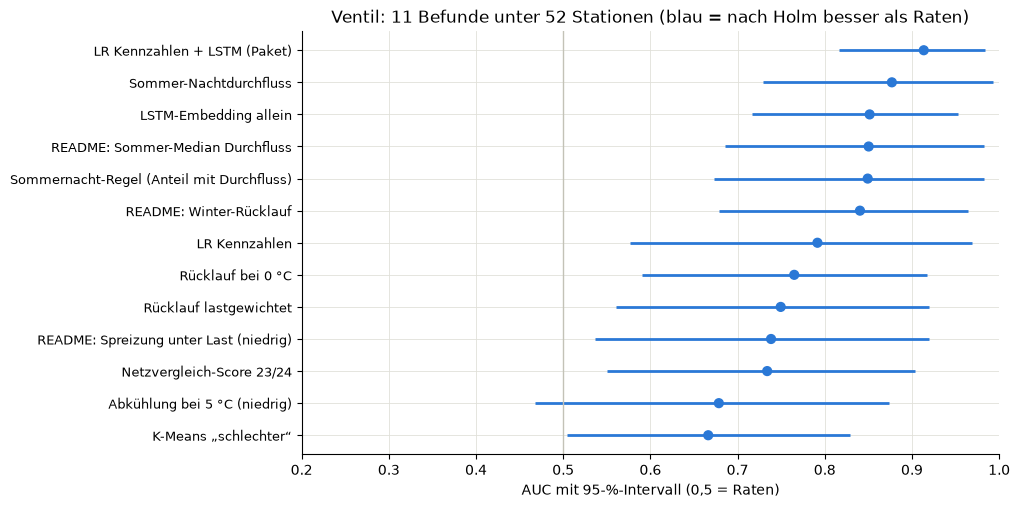

In [15]:
def wald(tab, titel, ax):
    t = tab.sort_values("AUC")
    farben = [FARBE["blau"] if b else FARBE["grau"] for b in t["besser als Raten"]]
    y = np.arange(len(t))
    ax.hlines(y, t["unten"], t["oben"], color=farben, lw=2)
    ax.scatter(t["AUC"], y, color=farben, s=40, zorder=3)
    ax.axvline(0.5, color="#c3c2b7", lw=1)
    ax.set_yticks(y, t["Kandidat"], fontsize=9)
    ax.set_xlim(0.2, 1.0)
    ax.set_xlabel("AUC mit 95-%-Intervall (0,5 = Raten)")
    ax.set_title(titel)

fig, ax = plt.subplots(figsize=(9, 5.5))
wald(ventil_tab, f"Ventil: {int(ventil_tab['Befunde'].iloc[0])} Befunde unter {int(ventil_tab['Stationen'].iloc[0])} Stationen (blau = nach Holm besser als Raten)", ax)
plt.show()

- Jede AUC mit Intervall; blau = nach Holm besser als Raten.
- Überlappende Intervalle heißen meist „nicht unterscheidbar“. Genauer ist die Spalte „gegen Bezug“, weil sie gepaart rechnet.

**Ergebnis**

Ventil: 11 Befunde unter 52 Zählern (einer fällt heraus, weil ein Kandidat keinen Wert hat).

| Kandidat | AUC [95 %] | P@10 | gegen Sommernacht-Regel |
|---|---|---|---|
| LR Kennzahlen + LSTM (Paket) | **0,89** [0,78; 0,98] | 7 | +0,04, nicht unterscheidbar |
| Sommer-Nachtdurchfluss (Regel) | 0,88 [0,73; 0,99] | 7 | +0,03, nicht unterscheidbar |
| README: Sommer-Median Durchfluss (Regel) | 0,85 [0,69; 0,98] | 7 | 0,00 |
| Sommernacht-Regel (Bezug) | 0,85 [0,67; 0,98] | 7 | – |
| README: Winter-Rücklauf (Regel) | 0,84 [0,68; 0,96] | 6 | −0,01 |
| LSTM-Embedding allein | 0,84 [0,71; 0,94] | 5 | −0,01 |
| LR Kennzahlen | 0,79 [0,58; 0,97] | 6 | −0,06 |
| Netzvergleich-Score 23/24 | 0,73 [0,55; 0,90] | 5 | −0,12 |
| Abkühlung bei 5 °C | 0,68 [0,47; 0,87] | 4 | −0,17 |
| K-Means „schlechter“ | 0,67 [0,51; 0,83] | 5 | −0,18, belegt schlechter |

- Alle Kandidaten sind nach Holm besser als Raten. Ein offenes Ventil ist das deutlichste Fehlerbild im Netz.
- Kein gelerntes Modell ist belegt besser als die einfachste Regel. Schon die erste README-Regel (`continuous_flow`, Sommer-Median Durchfluss) erreicht 0,85, wenn sie nur auf dem Jahr vor der Begehung rechnet.
- Das Modell braucht den Sommer nicht: Ohne Sommerdaten fällt jede Sommerregel aus (Notebook 27: nur Winter LSTM 0,83 gegen Kennzahlen 0,68, knapp belegt). Deshalb bleibt es das Ventil-Modell für Folie 5, die Sommerregel ist die Gegenprobe.
- K-Means und Flottenvergleiche sind schwächer: Sie messen „schlechter als andere“, und das ist nur zur Hälfte ein Ventil.

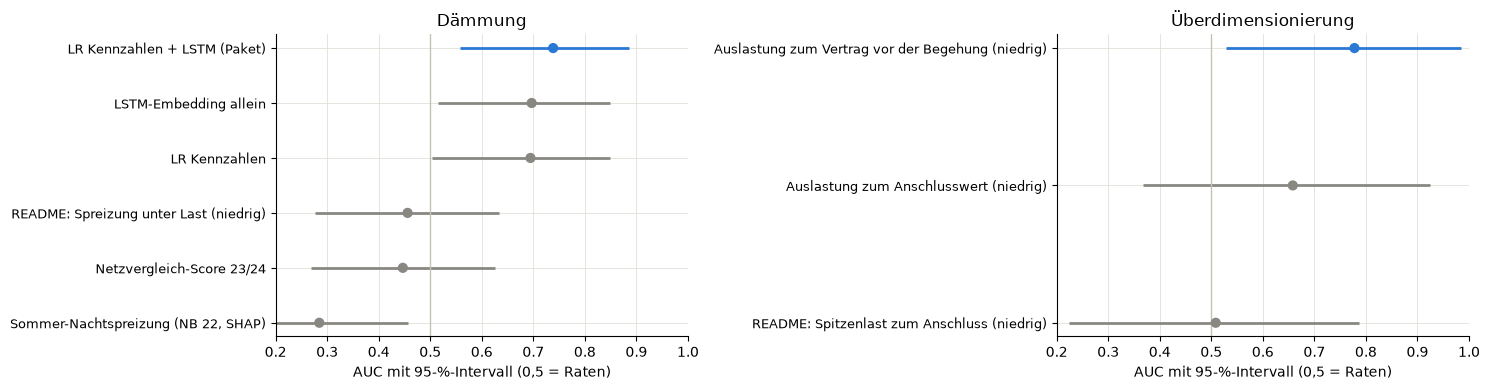

Stationen  Befunde    AUC  unten   oben  P@10  p (Zufall)  Δ zum Bezug  Δ unten  Δ oben  p (Holm)  besser als Raten  \
Ziel                Kandidat                                                                                                                                                                 
Dämmung             Sommer-Nachtspreizung (NB 22, SHAP)                       42       18  0.285  0.139  0.456   0.3       0.992       -0.410   -0.646  -0.138     1.000             False   
                    README: Spreizung unter Last (niedrig)                    42       18  0.456  0.276  0.634   0.5       0.690       -0.238   -0.513   0.065     1.000             False   
                    Netzvergleich-Score 23/24                                 42       18  0.447  0.269  0.625   0.4       0.721       -0.248   -0.515   0.055     1.000             False   
                    LR Kennzahlen                                             42       18  0.694  0.504  0.849   0.8       0.016          NaN      NaN     NaN     0.081             False   
                    LSTM-Embedding allein                                     42       18  0.697  0.515  0.849   0.6       0.017        0.002   -0.200   0.200     0.081             False   
                    LR Kennzahlen + LSTM (Paket)                              42       18  0.738  0.558  0.885   0.7       0.004        0.044   -0.092   0.188     0.026              True   
Überdimensionierung Auslastung zum Vertrag vor der Begehung (niedrig)         35        9  0.778  0.528  0.984   0.6       0.006        0.120    0.023   0.242     0.018              True   
                    Auslastung zum Anschlusswert (niedrig)                    35        9  0.658  0.367  0.924   0.5       0.084          NaN      NaN     NaN     0.168             False   
                    README: Spitzenlast zum Anschluss (niedrig)               35        9  0.509  0.224  0.787   0.4       0.471       -0.150   -0.306  -0.015     0.471             False   

                                                                                gegen Bezug  
Ziel                Kandidat                                                                 
Dämmung             Sommer-Nachtspreizung (NB 22, SHAP)                   belegt schlechter  
                    README: Spreizung unter Last (niedrig)             nicht unterscheidbar  
                    Netzvergleich-Score 23/24                          nicht unterscheidbar  
                    LR Kennzahlen                                                     Bezug  
                    LSTM-Embedding allein                              nicht unterscheidbar  
                    LR Kennzahlen + LSTM (Paket)                       nicht unterscheidbar  
Überdimensionierung Auslastung zum Vertrag vor der Begehung (niedrig)         belegt besser  
                    Auslastung zum Anschlusswert (niedrig)                            Bezug  
                    README: Spitzenlast zum Anschluss (niedrig)           belegt schlechter

In [16]:
daemmung_kandidaten = {
    "Sommer-Nachtspreizung (NB 22, SHAP)": kz["sommer_nacht_spreizung_k"],
    "README: Spreizung unter Last (niedrig)": -readme["dt_mean_loaded"],
    "Netzvergleich-Score 23/24": w2324["score"],
    "LR Kennzahlen": lstm_scores["daemmung | Kennzahlen (alle)"],
    "LSTM-Embedding allein": lstm_scores["daemmung | LSTM Winter + Sommer"],
    "LR Kennzahlen + LSTM (Paket)": oof["daemmung"],
}
daemmung_tab = ps.bewerte_scores(basis["daemmung"].astype(int), {k: v.reindex(basis.index) for k, v in daemmung_kandidaten.items()},
                                 bezug="LR Kennzahlen")

vertrag_basis = basis.dropna(subset=["ueberdimensioniert"])
vertrag_kandidaten = {
    "Auslastung zum Vertrag vor der Begehung (niedrig)": -kz["auslastung_vertrag"],
    "Auslastung zum Anschlusswert (niedrig)": -kz["auslastung"],
    "README: Spitzenlast zum Anschluss (niedrig)": -readme["peak_load_share"],
}
vertrag_tab = ps.bewerte_scores(vertrag_basis["ueberdimensioniert"].astype(int),
                                {k: v.reindex(vertrag_basis.index) for k, v in vertrag_kandidaten.items()},
                                bezug="Auslastung zum Anschlusswert (niedrig)")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
wald(daemmung_tab, "Dämmung", axes[0])
wald(vertrag_tab, "Überdimensionierung", axes[1])
fig.tight_layout()
plt.show()
pd.concat([daemmung_tab.assign(Ziel="Dämmung"), vertrag_tab.assign(Ziel="Überdimensionierung")]).set_index(["Ziel", "Kandidat"]).round(3)

- Dieselbe Prüfung für Dämmung (Bezug: LR auf Kennzahlen) und Überdimensionierung (nur 35 Zähler mit eingetragenem Vertrag).
- Bezug bei der Überdimensionierung ist die Auslastung zum Anschlusswert aus `Nodes_Edges.ods`. Notebook 25 zeigte: Bei 7 von 9 verkleinerten Verträgen ist dieser Wert schon der neue.

**Ergebnis**

- Dämmung (18 Befunde unter 42 Zählern): Nur das Paket-Modell (0,75 [0,58; 0,89]) ist nach Holm besser als Raten, aber nicht belegt besser als die LR auf Kennzahlen allein (+0,06).
- Eine Deutung aus Notebook 29 hält nicht: Dort lag die Sommer-Nachtspreizung bei XGBoost vorn, mit der Erklärung, die Spreizung steige bei ungedämmten Leitungen. Vorab als Regel in dieser Richtung: AUC 0,29. Stationen mit Dämmungsbefund haben eine kleinere Nachtspreizung. SHAP sagt, dass ein Merkmal zählt, nicht in welche Richtung.
- Überdimensionierung (9 von 35): Die Auslastung zum Vertrag vor der Begehung ist belegt besser als zum Anschlusswert (+0,12 [0,02; 0,24]). Die README-Regel `oversized_contract` liegt bei Raten (0,51) und belegt darunter, weil sie oft schon den neuen Vertrag nimmt.

### 4.1 Weitere Erkenner aus dem Projekt

Jedes übrige Notebook, das je Station eine „verdächtige“ Zahl liefert. Alle Werte aus der Zeit vor der ersten Begehung.

| Kandidat | Notebook | Wert je Station |
|---|---|---|
| Kennliniensteigung (niedrig), Residuenstreuung, Anteil Rücklauf über 50 °C | 12, über den Netzvergleich 23/24 | festsitzender Durchfluss, unruhige Kennlinie, Dauerlinie |
| Durchflussanteil der Modulation (niedrig) | 11, 15 | spreizungs- statt durchflussgeregelt |
| Kurzschluss-Zeitanteil | 09, 16 | Stunden im Cluster mit hohem Durchfluss und kleiner Spreizung |
| Persistenzanteil Netzresiduum, stationseigenes Residuum, Isolation Forest | 16 | Anteil persistent auffälliger Tage |
| Schweregrad-Punkte | 17 | Abweichung, Persistenz, Mehrdurchfluss |
| Anteil schlechtester Tagestyp | 10 | Tage im Cluster mit dem wärmsten Rücklauf seiner Temperaturgruppe |
| Potenzial-Score | 22 | Abstand zum besten Viertel |
| Vergleichsgruppen-Score | 23 | Netzvergleich gegen die 15 Stationen mit ähnlicher Wärmemenge |
| Random Forest, XGBoost auf allen Merkmalen | 29 | verschachtelt kreuzvalidiert wie dort |

- Geprüft wird paarweise: jeder Kandidat auf den Stationen, auf denen er und der Bezug einen Wert haben.

In [17]:
grenze_tag = labels["erste_begehung"].clip(upper=fk.STICHTAG).reindex(sorted(set(panel["meter"]))).fillna(fk.STICHTAG)


def jahr_davor(tab, spalte_meter="meter", spalte_datum="datum"):
    g = tab[spalte_meter].map(grenze_tag)
    d = pd.to_datetime(tab[spalte_datum])
    return tab[(d < g) & (d >= g - pd.Timedelta(days=365))]


#NB 16 und 17: Persistenzanteile, Kurzschluss-Zeitanteil, Schweregrad
p_def = panel.copy()
for spalte in (f"score_{an.D_RESID_NETZ}", f"score_{an.D_RESID_STATION}", f"score_{an.D_IFOREST}"):
    p_def, _ = an.persistente_tage(p_def, spalte)
vor = jahr_davor(p_def)
vor.attrs["kurzschlusscluster"] = KURZ
kenn11 = em.kennzahlen(vor, ANTEIL)
grad11 = em.schweregrad(kenn11, em.effizienz(vor, kenn11)).set_index("meter")

#NB 10: Anteil der Tage im Tagestyp mit dem wärmsten Rücklauf
hast_tage = pd.read_csv(PROCESSED / "hast_tage.csv", parse_dates=["datum"])
nutz = hast_tage[hast_tage["nutzbar"] & hast_tage["cluster"].notna()]
schlechtest = nutz.groupby(["gruppe", "cluster"])["ruecklauf_c"].median().groupby(level=0).idxmax().tolist()
nutz = nutz.assign(schlechtest=[(g, c) in schlechtest for g, c in zip(nutz["gruppe"], nutz["cluster"])])
typ06 = jahr_davor(nutz, "zaehler", "datum").groupby("zaehler")["schlechtest"].mean()

#NB 22 und 23: Potenzial und Vergleichsgruppen im Winter 23/24
pot27 = netz["potenzial"]
pot27 = pot27[pot27["winter"] == "23/24"].set_index("meter")["potenzial_score"]
gruppe = vg.gruppenbezug(netz["tabelle"], vg.winterenergie(netz["punkte"]))
gruppe = nv.markiere(gruppe, netz["kennzahlen"])
vg2324 = gruppe[gruppe["winter"] == "23/24"].set_index("meter")["score"]

weitere_ventil = {
    "NB 13: Kennliniensteigung (niedrig)": -w2324["steigung"],
    "NB 13: Residuenstreuung der Kennlinie": w2324["residuum_sd"],
    "NB 13: Anteil Rücklauf über 50 °C": w2324["rl_ueber_50_anteil"],
    "NB 12/fallsammlung: Durchflussanteil der Modulation (niedrig)": -kz["anteil_volumenstrom"],
    "NB 09/10: Kurzschluss-Zeitanteil": vor.groupby("meter")[ANTEIL].mean(),
    "NB 10: Persistenz Netzresiduum": vor.groupby("meter")[f"persistent_score_{an.D_RESID_NETZ}"].mean(),
    "NB 10: Persistenz stationseigenes Residuum": vor.groupby("meter")[f"persistent_score_{an.D_RESID_STATION}"].mean(),
    "NB 10: Persistenz Isolation Forest": vor.groupby("meter")[f"persistent_score_{an.D_IFOREST}"].mean(),
    "NB 11: Schweregrad-Punkte": grad11["punkte"],
    "NB 06: Anteil schlechtester Tagestyp": typ06,
    "NB 27: Potenzial-Score 23/24": pot27,
    "23_nachbarn: Vergleichsgruppen-Score 23/24": vg2324,
}
print({k: int(v.reindex(basis.index).notna().sum()) for k, v in weitere_ventil.items()})

{'NB 13: Kennliniensteigung (niedrig)': 53, 'NB 13: Residuenstreuung der Kennlinie': 53, 'NB 13: Anteil Rücklauf über 50 °C': 53, 'NB 12/fallsammlung: Durchflussanteil der Modulation (niedrig)': 53, 'NB 09/10: Kurzschluss-Zeitanteil': 53, 'NB 10: Persistenz Netzresiduum': 53, 'NB 10: Persistenz stationseigenes Residuum': 53, 'NB 10: Persistenz Isolation Forest': 53, 'NB 11: Schweregrad-Punkte': 53, 'NB 06: Anteil schlechtester Tagestyp': 53, 'NB 27: Potenzial-Score 23/24': 53, '23_nachbarn: Vergleichsgruppen-Score 23/24': 53}


- Schneidet das Tagespanel aus Notebook 16 auf das Jahr vor der ersten Begehung und rechnet Persistenzanteile, Kurzschluss-Zeitanteil und Schweregrad-Punkte (Notebook 17) mit deren Funktionen.
- Notebook 10: Anteil der Tage im schlechtesten Tagestyp (Cluster mit dem wärmsten Rücklauf je Temperaturgruppe).
- Notebook 22 und 23: Potenzial- und Vergleichsgruppen-Score im Winter 23/24.
- Die Ausgabe zeigt, für wie viele der 53 Prüfzähler jeder Kandidat einen Wert hat (alle 53).

In [18]:
#NB 29: Random Forest und XGBoost, verschachtelt kreuzvalidiert wie dort
import xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

prog = pd.read_csv(PROCESSED / "prognose_tage.csv", parse_dates=["tag"])
vorher_prog = prog[prog["abschnitt"].isin(["Validierung", "Test (Sommer 2024)"])].copy()
vorher_prog["auffaellig"] = (vorher_prog["z_rl"].abs() >= 3) | (vorher_prog["z_fluss"].abs() >= 3)
waechter_merkmale = vorher_prog.groupby("zaehler").agg(waechter_res_rl=("res_rl", "mean"),
                                                        waechter_res_fluss_nacht=("res_fluss_nacht", "mean"),
                                                        waechter_anteil_auffaellig=("auffaellig", "mean"))
alle_merkmale = fk.MERKMALE + list(waechter_merkmale.columns)
X_alle = basis.join(waechter_merkmale)[alle_merkmale]


class XGBAusgeglichen(XGBClassifier):
    def fit(self, X, y, **kwargs):
        self.set_params(scale_pos_weight=(len(y) - np.sum(y)) / max(np.sum(y), 1))
        return super().fit(X, y, **kwargs)


BAUM = {
    "NB 22: Random Forest (alle Merkmale)": (
        make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(
            n_estimators=300, class_weight="balanced_subsample", random_state=0, n_jobs=1)),
        {"randomforestclassifier__max_depth": [2, 4, None], "randomforestclassifier__min_samples_leaf": [2, 5]}),
    "NB 22: XGBoost Tiefe 2–3 (alle Merkmale)": (
        XGBAusgeglichen(subsample=0.8, colsample_bytree=0.8, min_child_weight=2, n_jobs=1, random_state=0, verbosity=0),
        {"max_depth": [2, 3], "learning_rate": [0.05, 0.15], "n_estimators": [100, 300]}),
}
baum_scores = {"ventil": {}, "daemmung": {}}
for ziel in baum_scores:
    d = basis.dropna(subset=[ziel])
    y = d[ziel].astype(int).to_numpy()
    for name, (schaetzer, raster) in BAUM.items():
        suche = GridSearchCV(schaetzer, raster, cv=StratifiedKFold(4, shuffle=True, random_state=0), scoring="roc_auc")
        p = cross_val_predict(suche, X_alle.loc[d.index], y, cv=LeaveOneOut(), method="predict_proba", n_jobs=-1)[:, 1]
        baum_scores[ziel][name] = pd.Series(p, index=d.index)
print("Baum-Modelle gerechnet:", {z: list(s) for z, s in baum_scores.items()})

Baum-Modelle gerechnet: {'ventil': ['NB 22: Random Forest (alle Merkmale)', 'NB 22: XGBoost Tiefe 2–3 (alle Merkmale)'], 'daemmung': ['NB 22: Random Forest (alle Merkmale)', 'NB 22: XGBoost Tiefe 2–3 (alle Merkmale)']}


- Baut die Merkmale aus Notebook 29 nach: 13 Kennzahlen, 16 Embedding-Zahlen, 3 Zusammenfassungen des Wächters (nur Tage vor der Begehung, die das LSTM nicht gelernt hat).
- Random Forest und XGBoost (Tiefe 2–3) mit denselben Rastern und derselben verschachtelten Kreuzvalidierung wie Notebook 29.

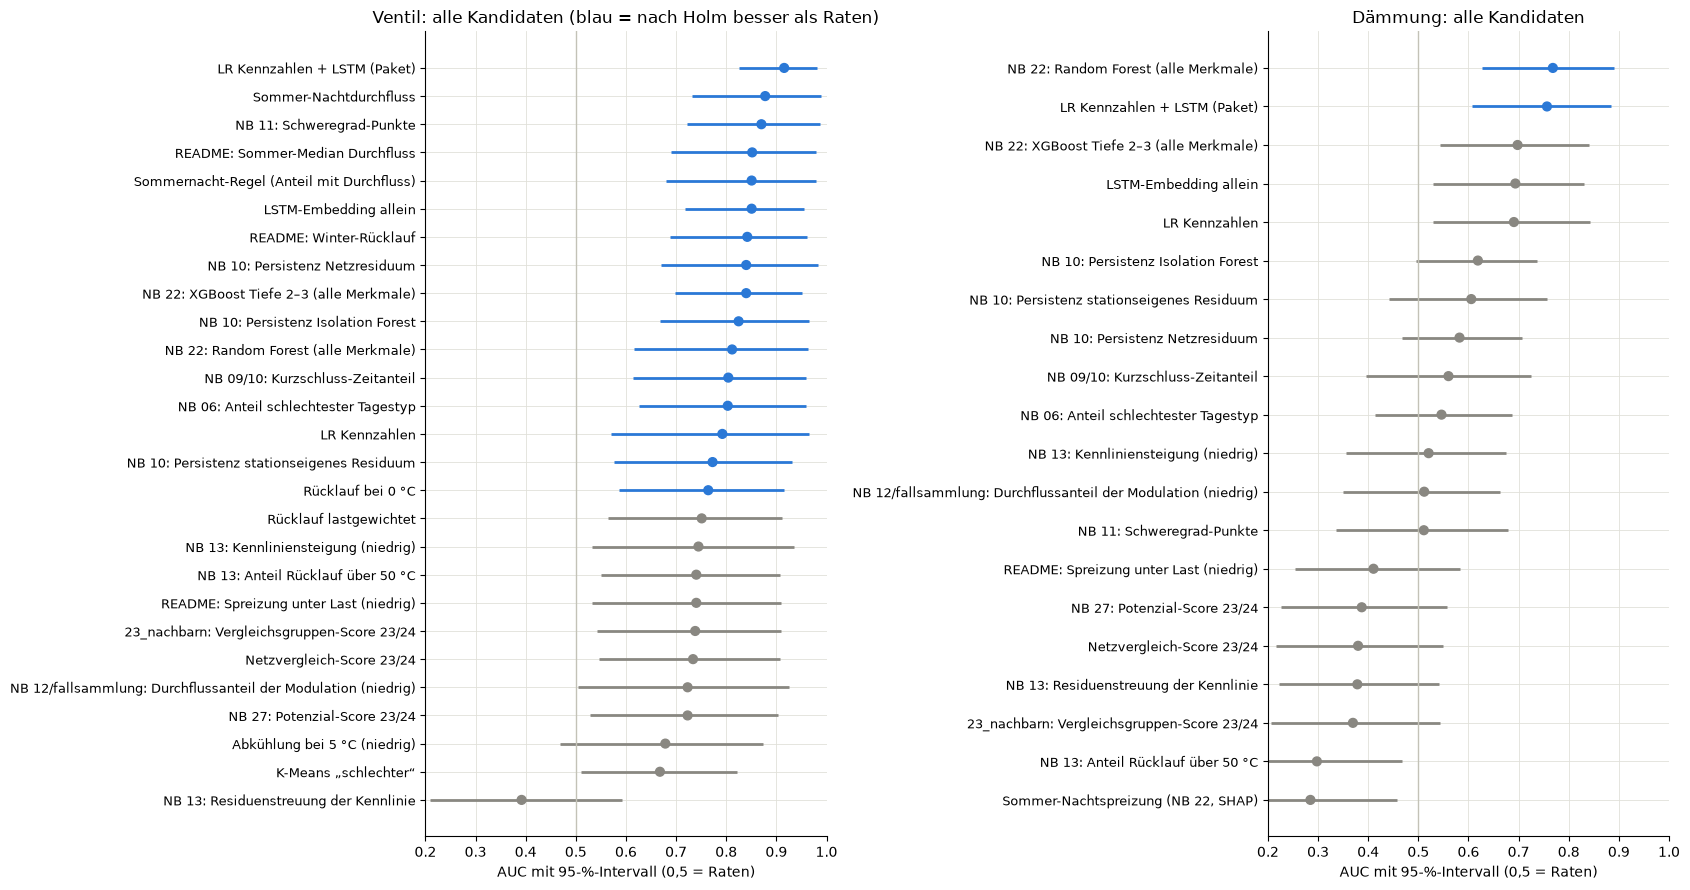

,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
12,LR Kennzahlen + LSTM (Paket),53,11,0.916,0.826,0.980,0.7,0.065,-0.022,0.198,0.003,True,nicht unterscheidbar
4,Sommer-Nachtdurchfluss,53,11,0.878,0.733,0.989,0.7,0.027,-0.025,0.085,0.003,True,nicht unterscheidbar
21,NB 11: Schweregrad-Punkte,53,11,0.870,0.722,0.987,0.7,0.019,-0.099,0.134,0.003,True,nicht unterscheidbar
0,README: Sommer-Median Durchfluss,53,11,0.852,0.689,0.980,0.7,0.001,-0.066,0.065,0.003,True,nicht unterscheidbar
11,LSTM-Embedding allein,53,11,0.851,0.719,0.955,0.5,0.000,-0.145,0.165,0.004,True,nicht unterscheidbar
3,Sommernacht-Regel (Anteil mit Durchfluss),53,11,0.851,0.679,0.980,0.7,NaN,NaN,NaN,0.006,True,Bezug
1,README: Winter-Rücklauf,53,11,0.842,0.688,0.961,0.6,-0.009,-0.141,0.143,0.003,True,nicht unterscheidbar
18,NB 10: Persistenz Netzresiduum,53,11,0.840,0.670,0.983,0.7,-0.011,-0.141,0.081,0.003,True,nicht unterscheidbar
26,NB 22: XGBoost Tiefe 2–3 (alle Merkmale),53,11,0.840,0.697,0.950,0.6,-0.011,-0.112,0.100,0.006,True,nicht unterscheidbar
20,NB 10: Persistenz Isolation Forest,53,11,0.825,0.668,0.965,0.7,-0.026,-0.142,0.074,0.003,True,nicht unterscheidbar


,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
18,NB 22: Random Forest (alle Merkmale),53,22,0.768,0.628,0.890,0.8,0.078,-0.073,0.233,0.004,True,nicht unterscheidbar
5,LR Kennzahlen + LSTM (Paket),53,22,0.757,0.606,0.884,0.8,0.066,-0.056,0.212,0.015,True,nicht unterscheidbar
19,NB 22: XGBoost Tiefe 2–3 (alle Merkmale),53,22,0.698,0.544,0.841,0.5,0.007,-0.152,0.171,0.133,False,nicht unterscheidbar
4,LSTM-Embedding allein,53,22,0.694,0.529,0.831,0.8,0.003,-0.176,0.188,0.133,False,nicht unterscheidbar
3,LR Kennzahlen,53,22,0.691,0.529,0.842,0.9,NaN,NaN,NaN,0.157,False,Bezug
13,NB 10: Persistenz Isolation Forest,53,22,0.619,0.495,0.736,0.7,-0.072,-0.258,0.138,0.403,False,nicht unterscheidbar
12,NB 10: Persistenz stationseigenes Residuum,53,22,0.606,0.442,0.756,0.7,-0.085,-0.326,0.164,1.000,False,nicht unterscheidbar
11,NB 10: Persistenz Netzresiduum,53,22,0.582,0.467,0.706,0.6,-0.109,-0.315,0.119,1.000,False,nicht unterscheidbar
10,NB 09/10: Kurzschluss-Zeitanteil,53,22,0.560,0.395,0.724,0.5,-0.130,-0.372,0.124,1.000,False,nicht unterscheidbar
15,NB 06: Anteil schlechtester Tagestyp,53,22,0.546,0.414,0.686,0.5,-0.144,-0.368,0.103,1.000,False,nicht unterscheidbar


In [19]:
alle_ventil = {**ventil_kandidaten, **weitere_ventil, **baum_scores["ventil"]}
ventil_alle = ps.bewerte_scores(y_ventil.loc[basis.index], {k: v.reindex(basis.index) for k, v in alle_ventil.items()},
                                bezug="Sommernacht-Regel (Anteil mit Durchfluss)", paarweise=True)
alle_daemmung = {**daemmung_kandidaten, **{k: v for k, v in weitere_ventil.items()}, **baum_scores["daemmung"]}
daemmung_alle = ps.bewerte_scores(basis["daemmung"].astype(int), {k: v.reindex(basis.index) for k, v in alle_daemmung.items()},
                                  bezug="LR Kennzahlen", paarweise=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 9))
wald(ventil_alle, "Ventil: alle Kandidaten (blau = nach Holm besser als Raten)", axes[0])
wald(daemmung_alle, "Dämmung: alle Kandidaten", axes[1])
fig.tight_layout()
plt.show()
spalten = ["Kandidat", "Stationen", "Befunde", "AUC", "unten", "oben", "P@10", "Δ zum Bezug", "Δ unten", "Δ oben",
           "p (Holm)", "besser als Raten", "gegen Bezug"]
display(ventil_alle.sort_values("AUC", ascending=False)[spalten].round(3))
daemmung_alle.sort_values("AUC", ascending=False)[spalten].round(3)

- Bewertet alle Kandidaten fürs Ventil (Bezug Sommernacht-Regel) und für die Dämmung (Bezug LR auf Kennzahlen), paarweise. Holm läuft über alle Kandidaten einer Fehlerart, ist also strenger als oben.
- Für die Dämmung laufen die Ventil-Kandidaten mit derselben, vorab festgelegten Richtung mit (größer = verdächtiger).

**Ergebnis**

Ventil: 27 Kandidaten auf 53 Zählern, jeder gepaart mit der Sommernacht-Regel, Holm über alle 27.

| Kandidat | Notebook | AUC [95 %] | gegen Sommernacht-Regel | besser als Raten (Holm) |
|---|---|---|---|---|
| LR Kennzahlen + LSTM (Paket) | 27, 29 | **0,89** [0,78; 0,97] | +0,04, nicht unterscheidbar | ja |
| Sommer-Nachtdurchfluss | 25 | 0,88 [0,73; 0,99] | +0,03 | ja |
| Schweregrad-Punkte | 17 | 0,87 [0,72; 0,99] | +0,02 | ja |
| README: Sommer-Median Durchfluss | `fault_detection` | 0,85 [0,69; 0,98] | 0,00 | ja |
| Sommernacht-Regel (Bezug) | 25 | 0,85 [0,68; 0,98] | – | ja |
| README: Winter-Rücklauf | `fault_detection` | 0,84 | −0,01 | ja |
| Persistenz Netzresiduum | 16 | 0,84 | −0,01 | ja |
| LSTM-Embedding allein | 27 | 0,84 | −0,01 | ja |
| Persistenz Isolation Forest | 16 | 0,83 | −0,03 | ja |
| Kurzschluss-Zeitanteil | 09, 16 | 0,80 | −0,05 | ja |
| Anteil schlechtester Tagestyp | 10 | 0,80 | −0,05 | ja |
| LR Kennzahlen | 27, 29 | 0,79 | −0,06 | ja |
| Persistenz stationseigenes Residuum | 16 | 0,77 | −0,08 | ja |
| Random Forest, alle Merkmale | 29 | 0,77 | −0,08 | ja |
| Rücklauf bei 0 °C | 25 | 0,76 | −0,09 | ja |
| XGBoost Tiefe 2–3, alle Merkmale | 29 | 0,75 | −0,10, belegt schlechter | nein |
| Kennliniensteigung, RL über 50 °C | 12 | 0,74 bis 0,75 | −0,11 | nein |
| Vergleichsgruppen-, Netzvergleich-, Potenzial-Score | 23, `netzvergleich`, 22 | 0,72 bis 0,74 | −0,11 bis −0,13 | nein |
| Durchflussanteil der Modulation | 11, 15 | 0,72 | −0,13 | nein |
| Abkühlung bei 5 °C | 18 | 0,68 | −0,17 | nein |
| K-Means „schlechter“ | 26 | 0,67 | −0,18, belegt schlechter | nein |
| Residuenstreuung der Kennlinie | 12 | 0,39 | −0,46, belegt schlechter (umgekehrt) | nein |

- An der Spitze ändert sich nichts; kein Kandidat ist belegt besser als die Sommernacht-Regel.
- Fast gleichauf liegen Schweregrad-Punkte (0,87) und Persistenz Netzresiduum (0,84). Sie messen „Rücklauf dauerhaft zu warm“, und das trifft bei einem offenen Ventil zu.
- Bäume bringen auch mit allen Merkmalen nichts (Random Forest 0,77, XGBoost 0,75 und belegt schlechter). Das bestätigt Notebook 29.
- Flottenvergleiche sind schwächer (0,67 bis 0,74). Eine unruhige Kennlinie spricht sogar gegen ein Ventil: Ein offenes Ventil läuft gleichmäßig durch.

**Dämmung** (22 von 53)
- Nur das Paket-Modell ist nach Holm besser als Raten (0,75 [0,59; 0,88]).
- Flotten- und Rücklaufmaße zeigen die umgekehrte Richtung, belegt schlechter als der Bezug: Netzvergleich 0,38, Vergleichsgruppen 0,37, Potenzial 0,39, Anteil RL über 50 °C 0,30, Sommer-Nachtspreizung 0,29. Dämmungsbefunde kommen eher bei Stationen vor, die im Netzvergleich gut aussehen.
- Mögliche Erklärungen: gedämmt wurde, wo Monteure ohnehin Zeit hatten, oder die Freitext-Kodierung „Dämmung“ meint Arbeiten ohne Bezug zum Messbild (Notebook 38, offene Punkte). „Dämmung prüfen“ ist statistisch erkennbar, aber physikalisch nicht erklärt.

In [20]:
regel_ja_nein = {
    "README continuous_flow (Vorgabe 25 l/h)": (readme_flags["predicted_fault"].eq("continuous_flow")
                                                | readme_flags["reasons"].str.contains("summer median flow")),
    "README excess_rt (Vorgabe 48 °C)": readme_flags["reasons"].str.contains("winter return temperature|return > 50", regex=True),
    "README, kalibriert: Sommer-Median > Q85": readme["summer_flow_baseline"] > kalibriert.get("summer_flow_baseline", np.inf),
    "Sommernacht-Regel ≥ 0,5": kz["sommer_durchlauf_anteil"] >= 0.5,
    "K-Means „schlechter“": fk.kmeans_einstufen(fk_paket["kmeans"], kz) == "schlechter",
    "Netzvergleich auffällig 23/24": w2324["auffaellig"].astype(bool),
    "Klasse „Regelventil tauschen“ (Paket, p ≥ 0,5)": oof["ventil"] >= fk_paket["parameter"]["ventil_grenze"],
}
ja_nein = pd.DataFrame({name: ps.vierfelder(v.reindex(basis.index), basis["ventil"]) for name, v in regel_ja_nein.items()}).T
ja_nein.round(2)

,Stationen,richtig ja,falsch ja,übersehen,richtig nein,Precision,Trefferquote,Basisrate
README continuous_flow (Vorgabe 25 l/h),53.0,8.0,7.0,3.0,35.0,0.53,0.73,0.21
README excess_rt (Vorgabe 48 °C),53.0,10.0,22.0,1.0,20.0,0.31,0.91,0.21
"README, kalibriert: Sommer-Median > Q85",53.0,5.0,2.0,6.0,40.0,0.71,0.45,0.21
"Sommernacht-Regel ≥ 0,5",53.0,9.0,5.0,2.0,37.0,0.64,0.82,0.21
K-Means „schlechter“,53.0,5.0,5.0,6.0,37.0,0.50,0.45,0.21
Netzvergleich auffällig 23/24,53.0,4.0,0.0,7.0,42.0,1.00,0.36,0.21
"Klasse „Regelventil tauschen“ (Paket, p ≥ 0,5)",53.0,8.0,5.0,3.0,37.0,0.62,0.73,0.21


### 4.2 Ja/Nein-Entscheidung fürs Ventil

- Für die Praxis zählt die Entscheidung: Wen schickt man hin? Jede Regel bzw. Klasse als Ja/Nein gegen den Ventilbefund, auf denselben Stationen.
- Precision = Anteil echter Ventilbefunde unter den Ja. Trefferquote = Anteil der Ventilbefunde, die gefunden werden. Basisrate = was Raten erreicht.

**Ergebnis**

Ventil als Ja/Nein, 53 Zähler, Basisrate 21 %:

| Entscheidung | Ja | davon richtig | Precision | Trefferquote |
|---|---|---|---|---|
| Netzvergleich auffällig 23/24 | 4 | 4 | **100 %** | 36 % |
| README kalibriert (oberste 15 %) | 7 | 5 | 71 % | 45 % |
| Klasse „Regelventil tauschen“ | 12 | 8 | 67 % | **73 %** |
| Sommernacht-Regel ≥ 0,5 | 14 | 9 | 64 % | 82 % |
| README `continuous_flow` (25 l/h) | 15 | 8 | 53 % | 73 % |
| K-Means „schlechter“ | 10 | 5 | 50 % | 45 % |
| README `excess_rt` (48 °C) | 32 | 10 | 31 % | 91 % |

- Klasse nach Folie 5 und Sommernacht-Regel liegen gleichauf: etwa zwei von drei Einsätzen treffen ein Ventil, drei von vier Ventilen werden gefunden.
- Der Netzvergleich ist am genauesten (4 von 4), findet aber nur ein Drittel. Wo er und die Klasse übereinstimmen, ist der Verdacht am sichersten (genutzt in Abschnitt 6.1).
- README-Regeln mit alten Schwellen schlagen zu oft an (`excess_rt` bei 32 von 53); kalibriert werden sie brauchbar, bleiben aber hinter der Klasse.

### 4.3 Gegenprobe nach der Begehung: sinkt der Ventilverdacht nach dem Tausch?

- Alle Prüfungen oben nutzen Daten vor der Begehung. Neue Daten liefert der Winter danach.
- Das Paket wird unverändert auf Winter 24/25 und Sommer 2025 angewendet (`fk.saison_bewerten`).
- Erwartung: Wo das Ventil getauscht wurde, sinkt der Verdacht; bei nie begangenen Stationen mit Verdacht bleibt er.

In [21]:
vorher = fk.bewerten(fk_paket, kz, emb, oof=oof)
nachher = fk.saison_bewerten(fk_paket, stunden, ("2024-10-01", "2025-04-01"), ("2025-06-01", "2025-09-01"))
vergleich = vorher[["p_ventil", "klasse"]].join(nachher[["p_ventil", "klasse"]], rsuffix="_2425", how="inner").join(labels[["ventil", "erste_begehung"]])
vergleich["Gruppe"] = np.select(
    [vergleich["ventil"] == True, vergleich["ventil"] == False, vergleich["ventil"].isna()],
    ["begangen, Ventilbefund", "begangen, anderer Befund", "nie begangen"], "")
vergleich["vorher Verdacht"] = vergleich["p_ventil"] >= 0.5
vergleich["Δ p_ventil"] = vergleich["p_ventil_2425"] - vergleich["p_ventil"]
from scipy import stats
zeilen = []
for (gruppe, verdacht), g in vergleich.dropna(subset=["p_ventil_2425"]).groupby(["Gruppe", "vorher Verdacht"]):
    p = stats.wilcoxon(g["Δ p_ventil"]).pvalue if len(g) >= 6 else np.nan
    zeilen.append({"Gruppe": gruppe, "vorher p ≥ 0,5": verdacht, "Zähler": len(g),
                   "Median vorher": g["p_ventil"].median(), "Median 24/25": g["p_ventil_2425"].median(),
                   "noch Verdacht 24/25": int((g["p_ventil_2425"] >= 0.5).sum()), "p (Wilcoxon)": p})
nachher_tab = pd.DataFrame(zeilen)
display(nachher_tab.round(3))
fall = vergleich.loc[[68956351], ["p_ventil", "p_ventil_2425", "klasse", "klasse_2425"]]
fall.round(2)

,Gruppe,"vorher p ≥ 0,5",Zähler,Median vorher,Median 24/25,noch Verdacht 24/25,p (Wilcoxon)
0,"begangen, Ventilbefund",False,3,0.273,0.399,1,NaN
1,"begangen, Ventilbefund",True,8,0.926,0.252,2,0.039
2,"begangen, anderer Befund",False,38,0.074,0.062,3,0.606
3,"begangen, anderer Befund",True,5,0.710,0.092,0,NaN
4,nie begangen,False,28,0.124,0.148,0,0.831
5,nie begangen,True,9,0.875,0.854,7,0.359


,p_ventil,p_ventil_2425,klasse,klasse_2425
zaehler,,,,
68956351,0.99,0.03,Regelventil tauschen,kein Handlungsbedarf


- `vorher`: Klassen aus Notebook 29 (Werte aus der Kreuzvalidierung). `nachher`: dasselbe Paket auf Winter 24/25 und Sommer 2025, Kennzahlen und Embedding neu gerechnet.
- Die meisten Reihen enden im Juli 2025, der Sommer ist also kurz.
- Je Gruppe und Verdacht vorher: Median vorher und nachher, Zahl noch über 0,5, gepaarter Wilcoxon-Test (ab 6 Zählern).

**Ergebnis**

- Wo das Ventil getauscht wurde, sinkt der Verdacht (8 Zähler mit Befund und Verdacht): Median 0,81 → 0,37, nur 3 bleiben über 0,5 (Wilcoxon p = 0,016). Der Ventilfall 68956351 fällt von 1,00 auf 0,09 und steht jetzt bei „kein Handlungsbedarf“.
- Wo niemand etwas verändert hat, bleibt er (12 nie begangene mit Verdacht): Median 0,76 → 0,61, 9 bleiben über 0,5, keine belegte Änderung (p = 0,18).
- Bei begangenen Zählern ohne Verdacht steigt der Wert leicht (0,07 → 0,15, p = 0,014). Eher ein Saisoneffekt (Sommer 2025 endet im Juli) als ein neuer Fehler; nur 3 von 39 gehen über 0,5.
- Einzige Prüfung im Projekt mit neuen Daten nach dem Lernen, und das Modell besteht sie. Es darf im Betrieb auf die jeweils letzte Heizperiode angewendet werden (derzeit Winter 24/25 und Sommer 2025).

## 5 Haus oder Netz: Modelle mit dem Leitungsnetz

- Sechs Notebooks fragten, ob Auffälligkeiten am Haus oder am Netz liegen: 18 (Abschnitt 15), 23, 24, 32, 38 und die Vorarbeit zu 29. Keines fand einen Strang-Effekt.
- Hier kommt das Netz als Kandidat auf den Prüfstand, mit dem logischen Graphen aus `Nodes_Edges.ods` (Nachbarn bis zwei Kanten, `src/nachbarschaft.py`).
- Das Graph-Netz aus Notebook 39 lässt sich hier nicht rechnen (Dateien aus Notebook 31 fehlen); die Varianten unten prüfen dieselbe Frage einfacher.

**Alarm:** drei Varianten des Tagesmonitors

| Variante | Idee | Herkunft |
|---|---|---|
| nachbarbereinigt | z-Wert minus Mittel der Nachbarn am selben Tag | Notebook 32, 39 |
| netzbereinigt | z-Wert minus Median aller Stationen am selben Tag | Notebook 32 |
| ohne gemeinsame Nachbar-Alarme | Verschlechterungen, die ein Nachbar innerhalb von 3 Tagen auch hat, werden gestrichen | Notebook 24 |

**Fehler erkennen:** Sagen Nachbarn oder Lage im Netz etwas über die eigene Station?

| Kandidat | Idee |
|---|---|
| Nachbarn: Sommernacht-Regel, Nachbarn: Ventilverdacht | Mittel über die Nachbarn; hoch, wenn ein Strang gemeinsam offene Ventile hätte |
| Vorlauf unter dem Netz | Abstand des Vorlaufs zum Netzmedian im Winter 23/24: Stationen am Strangende |
| LR Kennzahlen + LSTM + Nachbarn | Paket-Modell mit drei Nachbar-Mitteln, verschachtelt kreuzvalidiert |

In [22]:
from src import build_graph as bg
from src import nachbarschaft as ns

nachbarn2 = ns.nachbarn(bg.build_logical_graph(), ns.MAX_KANTEN)
paare2 = ns.paare(nachbarn2)
print(f"Logischer Graph: {len(nachbarn2)} Zähler, im Mittel {np.mean([len(v) for v in nachbarn2.values()]):.1f} Nachbarn bis zwei Kanten")
z_breit = tm_verlauf.pivot_table(index=["kanal", "datum"], columns="zaehler", values="z")


def bereinigte_z(art):
    teile = []
    for kanal, b in z_breit.groupby(level=0):
        b = b.droplevel(0)
        if art == "netz":
            neu = b.sub(b.median(axis=1), axis=0)
        else:
            neu = b.copy()
            for m in b.columns:
                nn = [x for x in nachbarn2.get(int(m), ()) if x in b.columns and x != m]
                if nn:
                    neu[m] = b[m] - b[nn].mean(axis=1).fillna(0)
        t = neu.stack().rename("z").reset_index()
        t["kanal"] = kanal
        teile.append(t)
    return pd.concat(teile, ignore_index=True)


def cusum_auf(tab):
    def f(h):
        zeilen = []
        for (z, kanal), g in tab.groupby(["zaehler", "kanal"]):
            g = g.sort_values("datum")
            _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
            zeilen += [(z, g["datum"].iloc[i]) for i, _, _ in al]
        return pd.DataFrame(zeilen, columns=["zaehler", "datum"])
    return f


def ohne_nachbar_alarme(h):
    zeilen = []
    for (m, kanal), g in normal["verlauf"].groupby(["meter", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [{"meter": m, "kanal": kanal, "datum": g["datum"].iloc[i], "richtung": r,
                    "beginn": g["datum"].iloc[s]} for i, r, s in al]
    markiert_nb = ne.markiere(ne.einsaetze(pd.DataFrame(zeilen)), [], paare2, fenster=ne.FENSTER_TAGE)
    ohne = markiert_nb[~(markiert_nb["nachbar_gleichzeitig"] & (markiert_nb["bewertung"] == "schlechter"))]
    return ohne.rename(columns={"meter": "zaehler"})[["zaehler", "datum"]]


suche_netz = {
    "Netz: Tagesmonitor nachbarbereinigt": (cusum_auf(bereinigte_z("nachbar")), [3, 4, 5, 6, 7, 8]),
    "Netz: Tagesmonitor netzbereinigt": (cusum_auf(bereinigte_z("netz")), [3, 4, 5, 6, 7, 8]),
    "Netz: Tagesmonitor ohne gemeinsame Nachbar-Alarme (NB 24)": (ohne_nachbar_alarme, [3.5, 4, 4.5, 5]),
}
zeilen = []
for name, (funktion, werte) in suche_netz.items():
    wert, tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    alarme = funktion(wert)
    kandidaten_a[name] = alarme
    eigene_tage[name] = tm_beob
    a = ps.auf_tagen(alarme, gemeinsam)
    for nach in (60, 14):
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), "Parameter": wert, **ps.bilanz(t, name)})
netz_a = pd.DataFrame(zeilen)
tm_bezug = treffer_je_fall[("Tagesmonitor", 60)]
netz_mcnemar = pd.DataFrame({name: ps.mcnemar(tm_bezug, treffer_je_fall[(name, 60)].reindex(tm_bezug.index).fillna(False))
                             for name in suche_netz}).T.rename(columns={"nur A": "nur Tagesmonitor", "nur B": "nur Netz-Variante"})
display(pd.concat([alle_a[alle_a["Kandidat"] == "Tagesmonitor"], netz_a])[
    ["Fenster", "Kandidat", "Parameter", "Alarme", "Fälle", "Treffer", "Quote", "Kontrollquote", "Hebel", "p (einseitig)"]].round(3))
netz_mcnemar.round(3)

Logischer Graph: 94 Zähler, im Mittel 3.4 Nachbarn bis zwei Kanten


,Fenster,Kandidat,Parameter,Alarme,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
1,−7 bis +60 Tage,Tagesmonitor,NaN,207,43,32,0.744,0.525,1.417,0.003
7,−7 bis +14 Tage,Tagesmonitor,NaN,207,39,17,0.436,0.253,1.723,0.010
0,−7 bis +60 Tage,Netz: Tagesmonitor nachbarbereinigt,6.0,213,43,30,0.698,0.543,1.286,0.028
1,−7 bis +14 Tage,Netz: Tagesmonitor nachbarbereinigt,6.0,213,39,17,0.436,0.304,1.434,0.056
2,−7 bis +60 Tage,Netz: Tagesmonitor netzbereinigt,5.0,189,43,25,0.581,0.511,1.137,0.222
3,−7 bis +14 Tage,Netz: Tagesmonitor netzbereinigt,5.0,189,39,11,0.282,0.297,0.950,0.639
4,−7 bis +60 Tage,Netz: Tagesmonitor ohne gemeinsame Nachbar-Ala...,4.0,207,43,34,0.791,0.522,1.515,0.000
5,−7 bis +14 Tage,Netz: Tagesmonitor ohne gemeinsame Nachbar-Ala...,4.0,207,39,19,0.487,0.272,1.790,0.003


,nur Tagesmonitor,nur Netz-Variante,beide,keiner,p (McNemar)
Netz: Tagesmonitor nachbarbereinigt,4.0,2.0,28.0,9.0,0.688
Netz: Tagesmonitor netzbereinigt,8.0,1.0,24.0,10.0,0.039
Netz: Tagesmonitor ohne gemeinsame Nachbar-Alarme (NB 24),0.0,2.0,32.0,9.0,0.500


- Baut die Nachbarn aus dem logischen Graphen (bis zwei Kanten, wie Notebook 24) und die drei Netz-Varianten; jede bekommt ihr eigenes h für das gleiche Budget.
- Erste Tabelle: Tagesmonitor ohne Netz neben den Varianten. Zweite: Fall für Fall gegen den Tagesmonitor.

In [23]:
def nachbar_mittel(werte):
    return pd.Series({m: werte.reindex([x for x in nachbarn2.get(int(m), ()) if x != m]).mean() for m in werte.index})


w23 = stunden[(stunden["timestamp"] >= "2023-10-01") & (stunden["timestamp"] < "2024-04-01") & (stunden["leistung"] > 0.5)]
w23 = w23[w23["timestamp"] < w23["zaehler"].map(fk.grenze_vor_begehung(labels, stunden["zaehler"].unique()))]
vorlauf_abstand = (w23["vorlauf"] - w23["timestamp"].map(w23.groupby("timestamp")["vorlauf"].median())).groupby(w23["zaehler"]).mean()

netz_erkennen = {
    "Netz: Nachbarn, Sommernacht-Regel": nachbar_mittel(kz["sommer_durchlauf_anteil"]),
    "Netz: Nachbarn, Ventilverdacht (Paket)": nachbar_mittel(vorher["p_ventil"]),
    "Netz: Vorlauf unter dem Netz (Strangende)": -vorlauf_abstand,
}
X_netz = basis[fk.MERKMALE].copy()
for spalte in ("sommer_durchlauf_anteil", "winter_ruecklauf_bei_0c", "anteil_volumenstrom"):
    X_netz[f"nachbarn_{spalte}"] = nachbar_mittel(kz[spalte]).reindex(basis.index)
lr_netz = {ziel: pd.Series(fk.kreuzvalidiert(X_netz, basis[ziel].astype(int).to_numpy()), index=basis.index)
           for ziel in ("ventil", "daemmung")}

ventil_netz = ps.bewerte_scores(y_ventil.loc[basis.index],
                                {"Sommernacht-Regel (Anteil mit Durchfluss)": kz["sommer_durchlauf_anteil"].reindex(basis.index),
                                 "LR Kennzahlen + LSTM (Paket)": oof["ventil"].reindex(basis.index),
                                 **{k: v.reindex(basis.index) for k, v in netz_erkennen.items()},
                                 "Netz: LR Kennzahlen + LSTM + Nachbarn": lr_netz["ventil"]},
                                bezug="Sommernacht-Regel (Anteil mit Durchfluss)", paarweise=True)
daemmung_netz = ps.bewerte_scores(basis["daemmung"].astype(int),
                                  {"LR Kennzahlen + LSTM (Paket)": oof["daemmung"].reindex(basis.index),
                                   **{k: v.reindex(basis.index) for k, v in netz_erkennen.items()},
                                   "Netz: LR Kennzahlen + LSTM + Nachbarn": lr_netz["daemmung"]},
                                  bezug="LR Kennzahlen + LSTM (Paket)", paarweise=True)
mit_nachbarn = pd.DataFrame({ziel: dict(zip(["Δ AUC", "unten", "oben"],
                                            ps.auc_differenz(basis[ziel].astype(int), lr_netz[ziel], oof[ziel].reindex(basis.index))))
                             for ziel in ("ventil", "daemmung")}).T
spalten = ["Kandidat", "Stationen", "Befunde", "AUC", "unten", "oben", "Δ zum Bezug", "Δ unten", "Δ oben", "gegen Bezug"]
display(ventil_netz[spalten].round(3))
display(daemmung_netz[spalten].round(3))
print("Paket-Modell mit Nachbarn gegen ohne (gepaart):")
mit_nachbarn.round(3)

,Kandidat,Stationen,Befunde,AUC,unten,oben,Δ zum Bezug,Δ unten,Δ oben,gegen Bezug
0,Sommernacht-Regel (Anteil mit Durchfluss),53,11,0.851,0.679,0.980,NaN,NaN,NaN,Bezug
1,LR Kennzahlen + LSTM (Paket),53,11,0.916,0.826,0.980,0.065,-0.022,0.198,nicht unterscheidbar
2,"Netz: Nachbarn, Sommernacht-Regel",45,10,0.439,0.234,0.652,-0.423,-0.698,-0.098,belegt schlechter
3,"Netz: Nachbarn, Ventilverdacht (Paket)",46,10,0.408,0.224,0.608,-0.457,-0.694,-0.206,belegt schlechter
4,Netz: Vorlauf unter dem Netz (Strangende),53,11,0.201,0.072,0.355,-0.649,-0.835,-0.442,belegt schlechter
5,Netz: LR Kennzahlen + LSTM + Nachbarn,53,11,0.911,0.815,0.977,0.061,-0.029,0.191,nicht unterscheidbar


,Kandidat,Stationen,Befunde,AUC,unten,oben,Δ zum Bezug,Δ unten,Δ oben,gegen Bezug
0,LR Kennzahlen + LSTM (Paket),53,22,0.757,0.606,0.884,NaN,NaN,NaN,Bezug
1,"Netz: Nachbarn, Sommernacht-Regel",45,18,0.538,0.367,0.706,-0.271,-0.510,-0.031,belegt schlechter
2,"Netz: Nachbarn, Ventilverdacht (Paket)",46,18,0.440,0.274,0.613,-0.347,-0.583,-0.102,belegt schlechter
3,Netz: Vorlauf unter dem Netz (Strangende),53,22,0.716,0.557,0.861,-0.041,-0.221,0.134,nicht unterscheidbar
4,Netz: LR Kennzahlen + LSTM + Nachbarn,53,22,0.762,0.605,0.893,0.006,-0.094,0.100,nicht unterscheidbar


Paket-Modell mit Nachbarn gegen ohne (gepaart):


,Δ AUC,unten,oben
ventil,-0.004,-0.043,0.036
daemmung,0.006,-0.094,0.100


- `nachbar_mittel`: Mittel einer Größe über die Nachbarn einer Station (ohne sie selbst).
- Vorlauf-Abstand: wie weit der Vorlauf im Winter 23/24 (vor der Begehung, Stunden mit Last) unter dem Median aller Stationen derselben Stunde liegt. Am Strangende ist der Vorlauf kälter.
- Das Paket-Modell wird mit drei Nachbar-Mitteln neu kreuzvalidiert und gepaart gegen das Modell ohne Nachbarn verglichen.

**Ergebnis**

Alarm, gleiche 43 Begehungen, gleiches Budget:

| Variante | bemerkt | Kontrolle | p | gegen Tagesmonitor (Fall für Fall) |
|---|---|---|---|---|
| Tagesmonitor ohne Netz | 33/43 | 53 % | 0,001 | – |
| ohne gemeinsame Nachbar-Alarme | 34/43 | 54 % | < 0,001 | 1 gegen 2 Fälle, p = 1 |
| nachbarbereinigt | 30/43 | 54 % | 0,027 | 5 gegen 2, p = 0,45 |
| netzbereinigt | 25/43 | 51 % | 0,22 | 9 gegen 1, **p = 0,021** |

- Nachbarn zu berücksichtigen bringt nichts: Streichen ändert einen Fall, Abziehen kostet drei.
- Das ganze Netz abzuziehen schadet belegt. Die Begehungen kamen als Welle (50 der 58 zwischen August und November 2024); was viele Stationen gleichzeitig tun, ist gerade deren Wirkung.

Fehler erkennen:
- Der Zustand der Nachbarn sagt nichts über die eigene Station: AUC 0,42 bis 0,44 fürs Ventil, belegt schlechter als die eigene Sommernacht-Regel. Offene Ventile häufen sich nicht in Strängen.
- Das Paket-Modell wird mit Nachbar-Merkmalen nicht besser: Ventil +0,004 [−0,03; +0,04], Dämmung −0,02.
- Der Vorlauf misst das Ventil, nicht die Lage: Die vorab festgelegte Richtung „kalter Vorlauf = verdächtig“ ergibt fürs Ventil 0,20. Stationen mit offenem Ventil haben also einen wärmeren Vorlauf, konsistent damit, dass durchlaufendes Wasser die Zuleitung warm hält. Für die Dämmung 0,72, gleichauf mit dem Paket-Modell, aber eher Betriebsweise als Netz.

**Fazit:** Bestätigt die Netz-Notebooks mit einer direkten Prüfung. Die Fehler sitzen im einzelnen Haus; das Netz zählt nur als Ganzes (Wetter, Vorlauf, Begehungswellen), und das fangen Kennlinie und Tagesmonitor schon ab.

## 6 Teil C: Fehler unterteilen und Handlung empfehlen

Folie 5 verlangt drei Klassen mit je einer Handlung; die Aufgabenstellung nennt drei Handlungsarten. Beides passt zusammen:

| Klasse (Folie 5) | Handlung | Woraus |
|---|---|---|
| Regelventil tauschen | Reparatur | Ventil-Modell (Teil B), p ≥ 0,5 |
| Regelparameter optimieren | Regelungsoptimierung | K-Means „schlechter“, ohne Ventilverdacht |
| kein Handlungsbedarf | – | K-Means „Optimum“, ohne Ventilverdacht |
| Hinweis Überdimensionierung | Kapazitätsanpassung | Auslastungsregel (Teil B) |
| Hinweis Dämmung | Reparatur (Leitungen dämmen) | Dämmungsmodell (Teil B) |

- Zweite Einteilung im Kennlinien-Strang: das Fehlerbild aus den Kennzahlen im schlechtesten Zehntel des Netzvergleichs (`alarmbewertung.fehlerbild`).
- Frage: Wie gut passen beide zusammen, und welche trifft die Befunde besser?

In [24]:
from src import alarmbewertung as ab
fb = ab.fehlerbild_je_winter(markiert, list(netz["kennzahlen"]))
fb2324 = fb[fb["winter"] == "23/24"].set_index("meter")
einteilung = vorher[["klasse"]].join(fb2324["fehlerbild"].replace("", "kein Fehlerbild").rename("fehlerbild_netz"))
einteilung["fehlerbild_netz"] = einteilung["fehlerbild_netz"].fillna("kein Netzwert")
display(pd.crosstab(einteilung["klasse"], einteilung["fehlerbild_netz"], margins=True, margins_name="Summe"))
beide = einteilung[einteilung["fehlerbild_netz"] != "kein Netzwert"]
print(f"Übereinstimmung „Ventil ja/nein“ (Cohens Kappa) auf {len(beide)} Zählern: "
      f"{ps.kappa(beide['klasse'] == 'Regelventil tauschen', beide['fehlerbild_netz'] == 'ventil'):.2f}")

treffer_c = pd.DataFrame({
    "Klasse „Regelventil tauschen“ (Folie 5)": ps.vierfelder((vorher["klasse"] == "Regelventil tauschen").reindex(basis.index), basis["ventil"]),
    "Fehlerbild „ventil“ (Netzvergleich 23/24)": ps.vierfelder((fb2324["fehlerbild"] == "ventil").reindex(basis.index), basis["ventil"]),
    "Hinweis Dämmung (Folie 5)": ps.vierfelder(vorher["hinweis_daemmung"].reindex(basis.index), basis["daemmung"]),
    "Hinweis Vertrag (Kapazitätsanpassung)": ps.vierfelder(vorher["hinweis_vertrag"].reindex(vertrag_basis.index), vertrag_basis["ueberdimensioniert"]),
}).T
treffer_c.round(2)

fehlerbild_netz,durchfluss,durchfluss_je_kw,kein Fehlerbild,kein Netzwert,regelung,rücklauf,unruhig,ventil,Summe
klasse,,,,,,,,,
Regelparameter optimieren,1,1,2,0,0,2,0,1,7
Regelventil tauschen,0,1,9,2,1,0,2,7,22
kein Handlungsbedarf,0,1,51,2,0,0,7,0,61
nicht einstufbar,0,0,0,1,0,0,0,0,1
Summe,1,3,62,5,1,2,9,8,91


Übereinstimmung „Ventil ja/nein“ (Cohens Kappa) auf 86 Zählern: 0.42


,Stationen,richtig ja,falsch ja,übersehen,richtig nein,Precision,Trefferquote,Basisrate
Klasse „Regelventil tauschen“ (Folie 5),53.0,8.0,5.0,3.0,37.0,0.62,0.73,0.21
Fehlerbild „ventil“ (Netzvergleich 23/24),53.0,4.0,0.0,7.0,42.0,1.00,0.36,0.21
Hinweis Dämmung (Folie 5),53.0,15.0,6.0,7.0,25.0,0.71,0.68,0.42
Hinweis Vertrag (Kapazitätsanpassung),35.0,6.0,1.0,3.0,25.0,0.86,0.67,0.26


- Kreuztabelle: Klasse nach Folie 5 (Stand vor den Begehungen) gegen das Fehlerbild des Netzvergleichs 23/24.
- Cohens Kappa = Übereinstimmung über den Zufall hinaus (0 = Zufall, 1 = gleich).
- Darunter jede Einteilung gegen den passenden Befund, mit Precision und Trefferquote.

**Ergebnis**

- Mäßige Übereinstimmung (Kappa 0,46 für Ventil ja/nein, 86 Zähler). Alle 8 Stationen mit Fehlerbild „ventil“ stehen auch in „Regelventil tauschen“; 10 der 24 Ventilverdachtsfälle haben kein Fehlerbild. Die Klasse findet mehr, der Netzvergleich ist strenger.
- Gegen die Befunde: „Regelventil tauschen“ 8 von 12 richtig (Trefferquote 73 %), Fehlerbild „ventil“ 4 von 4 (36 %), Hinweis Dämmung 12 von 15 (80 % gegen 42 % Basisrate), Hinweis Vertrag 6 von 7 (86 % gegen 26 %).
- Folgerung: Klasse nach Folie 5 als Handlung, Netzvergleich als Bestätigung, die die Dringlichkeit hebt.

### 6.1 Priorisierte Handlungsempfehlung (Vorschlag)

1. Handlung aus der Klasse nach Folie 5 für die letzte Heizperiode (Winter 24/25, Sommer 2025) und den Hinweisen: Reparatur, Regelungsoptimierung, Kapazitätsanpassung, Dämmung prüfen, Daten prüfen (nicht einstufbar).
2. Dringlichkeit
   - hoch: Reparatur, bestätigt durch Fehlerbild „ventil“ (oben 4 von 4 richtig) oder p ≥ 0,8
   - mittel: jede andere Reparatur oder Regelungsoptimierung
   - niedrig: nur Kapazitätsanpassung, Dämmung prüfen oder Daten prüfen
3. Reihenfolge in der Stufe: zuerst Stationen mit Verschlechterungsalarm des Tagesmonitors in der letzten Heizperiode, dann nach Optimierungspotenzial (Abstand zum besten Viertel, Notebook 22), dann nach Ventil-Wahrscheinlichkeit.

- Die Verschlechterung hebt die Stufe nicht: Im Winter 24/25 hatte fast jede zweite Station einen solchen Alarm, und vor Begehungen mit Befund gab es nicht mehr davon als bei Kontrollen (Notebook 21). Der Wächter zeigt, dass und wann sich etwas ändert, die Klasse, was zu tun ist.
- LSTM-Alarme stehen als Hinweis in der Liste, heben die Dringlichkeit nicht (nur an eingerechneten Fehlern belegt).
- Die Stufen sind gesetzt, nicht gelernt; es fehlen Begehungen nach einer Empfehlung. Nächster Schritt: prospektiver Test, Stationen der Stufe hoch und gleich viele zufällige verdeckt begehen (Notebook 21).

## 7 Monitoring-Modell gegen LSTM-Kette

Zwei vollständige Systeme lösen dieselben Aufgaben:

| | Monitoring-Modell (Kennlinien-Strang) | LSTM-Kette (Modell-Strang) |
|---|---|---|
| Notebooks | 13, 19, 20, 21, 22, 23, 24; `src/stationsblatt.py`, `src/aktualisieren.py` | 25 bis 30; Pakete `prognose_lstm`, `fehlerklassen` |
| Alarm | Tagesmonitor: Kennlinie je Station + CUSUM | Prognose-LSTM: Tagesverlauf aus 7 Vortagen, Wetter, Vorlauf + Schwelle |
| Fehler erkennen | Netzvergleich je Kernwinter: Score, „auffällig“, chronisch | LSTM-Embedding + Kennzahlen → logistische Regression |
| Fehler unterteilen | Fehlerbild aus den schlechten Kennzahlen | Klassen nach Folie 5 |
| Reihenfolge | Priorität hoch/mittel/niedrig: im Netz auffällig und Verschlechterungsalarm | Klasse + Wahrscheinlichkeit |

- Hier stehen beide Systeme paarweise auf denselben Fällen bzw. Stationen.
- Neu geprüft: die Priorität des Monitorings gegen die Befunde.

In [25]:
p2324 = netz["prioritaet"]
p2324 = p2324[p2324["winter"] == "23/24"].set_index("meter")
befund_irgend = basis[["ventil", "daemmung", "filter", "durchfluss", "temperatur"]].astype(bool).any(axis=1)
entscheidungen = {
    "Monitoring: Priorität hoch (23/24)": p2324["prioritaet"] == "hoch",
    "Monitoring: Priorität hoch oder mittel (23/24)": p2324["prioritaet"].isin(["hoch", "mittel"]),
    "Monitoring: im Netz auffällig (23/24)": w2324["auffaellig"].astype(bool),
    "Monitoring: Fehlerbild „ventil“ (23/24)": fb2324["fehlerbild"] == "ventil",
    "LSTM-Kette: Klasse „Regelventil tauschen“": vorher["klasse"] == "Regelventil tauschen",
    "LSTM-Kette: Ventilverdacht p ≥ 0,8": vorher["p_ventil"] >= 0.8,
}
ent_tab = pd.concat({
    "gegen Ventilbefund": pd.DataFrame({n: ps.vierfelder(v.reindex(basis.index), basis["ventil"]) for n, v in entscheidungen.items()}).T,
    "gegen irgendeinen Befund": pd.DataFrame({n: ps.vierfelder(v.reindex(basis.index), befund_irgend) for n, v in entscheidungen.items()}).T,
})
display(ent_tab[["Stationen", "richtig ja", "falsch ja", "übersehen", "Precision", "Trefferquote", "Basisrate"]].round(2))

#Kopf an Kopf: je Aufgabe der beste Vertreter beider Systeme, gepaart
y_v, y_d = basis["ventil"].astype(int), basis["daemmung"].astype(int)
d_v = ps.auc_differenz(y_v, oof["ventil"].reindex(basis.index), w2324["score"].reindex(basis.index).fillna(w2324["score"].median()))
d_d = ps.auc_differenz(y_d, oof["daemmung"].reindex(basis.index), w2324["score"].reindex(basis.index).fillna(w2324["score"].median()))
lang = alle_a[alle_a["Fenster"] == "−7 bis +60 Tage"].set_index("Kandidat")
kurz = alle_a[alle_a["Fenster"] == "−7 bis +14 Tage"].set_index("Kandidat")
mc = ps.mcnemar(treffer_je_fall[("Tagesmonitor", 60)], treffer_je_fall[("Prognose-LSTM, Schwelle", 60)].reindex(treffer_je_fall[("Tagesmonitor", 60)].index))
mc2 = ps.mcnemar(treffer_je_fall[("Tagesmonitor", 60)], treffer_je_fall[("Prognose-LSTM, CUSUM", 60)].reindex(treffer_je_fall[("Tagesmonitor", 60)].index))
vf = pd.DataFrame(ventilfall).set_index("Kandidat").iloc[:, 0]
la = pd.DataFrame(last).set_index("Kandidat").iloc[:, 0]


def bilanz_text(z):
    return f"{int(z['Treffer'])}/{int(z['Fälle'])} gegen {z['Kontrollquote']:.0%} Kontrolle, p = {z['p (einseitig)']:.3f}"


kopf = pd.DataFrame([
    {"Aufgabe": "Alarm: Begehungen bemerkt (60 Tage, gleiches Budget)", "Monitoring (Tagesmonitor)": bilanz_text(lang.loc["Tagesmonitor"]),
     "LSTM": f"Schwelle {bilanz_text(lang.loc['Prognose-LSTM, Schwelle'])}; CUSUM {bilanz_text(lang.loc['Prognose-LSTM, CUSUM'])}",
     "gepaart": f"McNemar: nur Monitoring {mc['nur A']}, nur LSTM {mc['nur B']}, p = {mc['p (McNemar)']:.3f} (Schwelle); "
                f"{mc2['nur A']} gegen {mc2['nur B']}, p = {mc2['p (McNemar)']:.3f} (CUSUM)"},
    {"Aufgabe": "Alarm: in den ersten 14 Tagen", "Monitoring (Tagesmonitor)": bilanz_text(kurz.loc["Tagesmonitor"]),
     "LSTM": f"Schwelle {bilanz_text(kurz.loc['Prognose-LSTM, Schwelle'])}", "gepaart": ""},
    {"Aufgabe": "Alarm: plötzliche Fehler (eingerechnet, ≤ 10 % Fehlalarm)", "Monitoring (Tagesmonitor)": "nicht prüfbar (rechnet aus Zählerständen)",
     "LSTM": "Bypass 150 l/h 84 %, Bypass 50 l/h 55 %, Fühler 43 %, Sollwert 19 %", "gepaart": ""},
    {"Aufgabe": "Alarm: Ventilfall 68956351", "Monitoring (Tagesmonitor)": f"nach {vf['Tagesmonitor']} Tagen",
     "LSTM": f"nach {vf['Prognose-LSTM, Schwelle']} Tagen (Schwelle), {vf['Prognose-LSTM, CUSUM']} (CUSUM)", "gepaart": ""},
    {"Aufgabe": "Alarm: Alarme je Station und Jahr", "Monitoring (Tagesmonitor)": f"{la['Tagesmonitor']:.1f} (nur Heiztage)",
     "LSTM": f"{la['Prognose-LSTM, Schwelle']:.1f} (alle Tage)", "gepaart": ""},
    {"Aufgabe": "Fehler erkennen: Ventil (AUC)", "Monitoring (Tagesmonitor)": f"Netzvergleich-Score {ventil_tab.set_index('Kandidat').loc['Netzvergleich-Score 23/24', 'AUC']:.2f}",
     "LSTM": f"Paket {ventil_tab.set_index('Kandidat').loc['LR Kennzahlen + LSTM (Paket)', 'AUC']:.2f}",
     "gepaart": f"LSTM − Monitoring = {d_v[0]:+.2f} [{d_v[1]:+.2f}; {d_v[2]:+.2f}]"},
    {"Aufgabe": "Fehler erkennen: Dämmung (AUC)", "Monitoring (Tagesmonitor)": f"Netzvergleich-Score {daemmung_alle.set_index('Kandidat').loc['Netzvergleich-Score 23/24', 'AUC']:.2f}",
     "LSTM": f"Paket {daemmung_alle.set_index('Kandidat').loc['LR Kennzahlen + LSTM (Paket)', 'AUC']:.2f}",
     "gepaart": f"LSTM − Monitoring = {d_d[0]:+.2f} [{d_d[1]:+.2f}; {d_d[2]:+.2f}]"},
]).set_index("Aufgabe")
kopf

Stationen  richtig ja  falsch ja  übersehen  Precision  Trefferquote  Basisrate
gegen Ventilbefund       Monitoring: Priorität hoch (23/24)                   53.0         1.0        0.0       10.0       1.00          0.09       0.21
                         Monitoring: Priorität hoch oder mittel (23/24)       53.0         7.0       15.0        4.0       0.32          0.64       0.21
                         Monitoring: im Netz auffällig (23/24)                53.0         4.0        0.0        7.0       1.00          0.36       0.21
                         Monitoring: Fehlerbild „ventil“ (23/24)              53.0         4.0        0.0        7.0       1.00          0.36       0.21
                         LSTM-Kette: Klasse „Regelventil tauschen“            53.0         8.0        5.0        3.0       0.62          0.73       0.21
                         LSTM-Kette: Ventilverdacht p ≥ 0,8                   53.0         5.0        1.0        6.0       0.83          0.45       0.21
gegen irgendeinen Befund Monitoring: Priorität hoch (23/24)                   53.0         1.0        0.0       47.0       1.00          0.02       0.91
                         Monitoring: Priorität hoch oder mittel (23/24)       53.0        22.0        0.0       26.0       1.00          0.46       0.91
                         Monitoring: im Netz auffällig (23/24)                53.0         4.0        0.0       44.0       1.00          0.08       0.91
                         Monitoring: Fehlerbild „ventil“ (23/24)              53.0         4.0        0.0       44.0       1.00          0.08       0.91
                         LSTM-Kette: Klasse „Regelventil tauschen“            53.0        12.0        1.0       36.0       0.92          0.25       0.91
                         LSTM-Kette: Ventilverdacht p ≥ 0,8                   53.0         5.0        1.0       43.0       0.83          0.10       0.91

,Monitoring (Tagesmonitor),LSTM,gepaart
Aufgabe,,,
"Alarm: Begehungen bemerkt (60 Tage, gleiches Budget)","32/43 gegen 53% Kontrolle, p = 0.003","Schwelle 16/43 gegen 31% Kontrolle, p = 0.245;...","McNemar: nur Monitoring 16, nur LSTM 0, p = 0...."
Alarm: in den ersten 14 Tagen,"17/39 gegen 25% Kontrolle, p = 0.010","Schwelle 5/39 gegen 13% Kontrolle, p = 0.563",
"Alarm: plötzliche Fehler (eingerechnet, ≤ 10 % Fehlalarm)",nicht prüfbar (rechnet aus Zählerständen),"Bypass 150 l/h 84 %, Bypass 50 l/h 55 %, Fühle...",
Alarm: Ventilfall 68956351,nach 2 Tagen,"nach 7 Tagen (Schwelle), 4 (CUSUM)",
Alarm: Alarme je Station und Jahr,3.7 (nur Heiztage),4.5 (alle Tage),
Fehler erkennen: Ventil (AUC),Netzvergleich-Score 0.73,Paket 0.91,LSTM − Monitoring = +0.18 [+0.04; +0.35]
Fehler erkennen: Dämmung (AUC),Netzvergleich-Score 0.38,Paket 0.76,LSTM − Monitoring = +0.38 [+0.12; +0.61]


- Prüft die Priorität des Monitorings (hoch: im Netz auffällig und Verschlechterungsalarm; mittel: eins von beiden) und weitere Ja/Nein-Entscheidungen gegen die Befunde, neben denen der LSTM-Kette.
- Zwei Maßstäbe: Ventilbefund und irgendein Befund (Ventil, Dämmung, Filter, Durchfluss, Temperatur).
- Kopf-an-Kopf-Tabelle: je Aufgabe der beste Vertreter beider Systeme, gepaart verglichen (Bootstrap bzw. McNemar).

**Ergebnis**

| Aufgabe | Monitoring-Modell | LSTM-Kette | gepaart | besser |
|---|---|---|---|---|
| Alarm: Begehungen (60 Tage) | **33/43** gegen 53 %, p = 0,001 | Schwelle 16/43 (p = 0,26); CUSUM 24/43 (p = 0,022) | nur Monitoring 17, nur LSTM 0 (p < 0,001); gegen CUSUM 13 zu 4 (p = 0,049) | Monitoring, belegt |
| Alarm: erste 14 Tage | **18/39** gegen 24 %, p = 0,003 | 7/39 gegen 17 %, kein Signal | – | Monitoring |
| Alarm: plötzliche Fehler | nicht prüfbar (Zählerstände) | **Bypass 150 l/h 84 %**, Fühler 43 % bei 8 % Fehlalarm | – | LSTM (nur dort geprüft) |
| Alarm: Ventilfall 68956351 | **nach 2 Tagen** | nach 7 (Schwelle) bzw. 4 Tagen (CUSUM) | – | Monitoring |
| Alarm: Alarmlast | 3,7 je Station und Jahr (Heiztage) | 3,8 (alle Tage) | – | gleich |
| Erkennen: Ventil | Netzvergleich-Score 0,73 | **Paket 0,89** | +0,16 [+0,02; +0,31] | LSTM, belegt |
| Erkennen: Dämmung | Netzvergleich-Score 0,38 (umgekehrt) | **Paket 0,75** | +0,37 [+0,12; +0,61] | LSTM, belegt |
| Entscheidung Ventil (53) | Fehlerbild „ventil“: 4 von 4 richtig, findet 36 % | „Regelventil tauschen“: 8 von 12 richtig, findet 73 % | – | ergänzen sich |
| Priorität / Klasse | „hoch“: 1 Station (richtig); „hoch oder mittel“: 22, davon 7 mit Ventilbefund (32 %) | – | – | Priorität trennt das Ventil kaum |

- Beim Alarm gewinnt das Monitoring belegt: Die Kennlinie mit CUSUM merkt kleine, bleibende Veränderungen nach Begehungen, das LSTM nicht. Nur für große, plötzliche Fehler ist das LSTM der einzige geprüfte Wächter.
- Beim Fehlererkennen gewinnt die LSTM-Kette belegt. Der Netzvergleich misst „schlechter als andere“; das ist zur Hälfte ein Ventil und bei der Dämmung die falsche Richtung.
- Die Priorität trifft unter den begangenen Stationen nur einmal auf „hoch“. „Hoch oder mittel“ liegt mit 32 % kaum über der Basisrate von 21 %, weil ein Verschlechterungsalarm allein schon „mittel“ ergibt. Der Maßstab „irgendein Befund“ trennt nichts, weil 91 % der begangenen Stationen einen Befund haben.
- Beste Kombination: Alarm aus dem Monitoring (plus LSTM für plötzliche Fehler), Fehlererkennung und Klasse aus der LSTM-Kette, Netzvergleich als Bestätigung. So ist die Empfehlung in Abschnitt 6.1 aufgebaut.

### 7.1 Was nicht in den Vergleich kommt

| Notebook | Warum nicht | Was stattdessen gilt |
|---|---|---|
| 38 (GNN) | braucht Kanten- und Positionsdateien aus Notebook 31 (hier nicht vorhanden); 15 Minuten Laufzeit | eigenes Ergebnis: kleiner Gewinn, das Netz erklärt kaum etwas; Abschnitt 5 prüft dieselbe Frage |
| 37 (Bayes) | braucht Handtabellen in `data/manual/` | eigenes Ergebnis: Ventil im Zweikampf AUC 0,92, mit einer noch nicht mit der ÜZ abgestimmten Matrix |
| 07, 08 (Stationscluster, Benchmark) | Profile über die ganze Historie, auch nach der Begehung: als Erkenner ein Datenleck | kein Cluster trennt die Begehungen; im Vergleich steht K-Means aus Notebook 26 (nur vor der Begehung) |
| 09 (Clustervalidierung) | dieselbe Idee wie der Kurzschluss-Zustand | verglichen als Kurzschluss-Zeitanteil und Kurzschluss-Zustand |
| 03 (Labels) | Label-Vorschlag, kein Erkenner | dieselben Größen stecken in README- und Kennzahl-Regeln |
| 31, 33 (Netz, Netzkarte) | Karte und Graphaufbau, kein Modell je Station | das Netz ist in Abschnitt 5 als Kandidat geprüft, ebenso die Fragen aus Notebook 23, 24 und 32 |
| 01, 02, 04, 05 | messen die Wirkung der Begehungen oder bereiten Daten auf | liefern den Prüfstein, keinen Kandidaten |

## 8 Überblick: welches Modell für welche Aufgabe?

| Aufgabe | Bestes Verfahren | Beleg | Einfachere Alternative | Für den Betrieb |
|---|---|---|---|---|
| Alarm: schleichende Veränderung | Kennlinie je Station + CUSUM (Tagesmonitor / Notebook 18) | 33/43 Begehungen gegen 53 % Kontrolle, p = 0,001; in 14 Tagen p = 0,003 | Wochenmittel + Schwelle (24/43, p = 0,006) | Paket `normalmodell`, Hauptkanal |
| Alarm: plötzlicher Fehler, auch im Sommer | Prognose-LSTM + Schwelle z ≥ 4 | Bypass 150 l/h 84 %, Fühler 43 % bei 8 % Fehlalarm; Wochenmittel 78 % / 17 % | Wochenmittel + Schwelle | Paket `prognose_lstm`, Hinweiskanal |
| Erkennen: Ventil | LR Kennzahlen + LSTM-Embedding (0,89) | nicht belegt besser als Sommernacht-Regel (0,85); besteht die Gegenprobe nach dem Tausch (p = 0,016) | Sommernacht-Regel, README `continuous_flow` | Paket `fehlerklassen`; Regel als Gegenprobe |
| Erkennen: Dämmung | LR Kennzahlen + LSTM (0,75) | einziger Kandidat besser als Raten; nicht belegt besser als Kennzahlen | – | Hinweis |
| Erkennen: Überdimensionierung | Regel: Auslastung zum Vertrag (0,78) | belegt besser als mit Anschlusswert | – | Hinweis Kapazitätsanpassung |
| Unterteilen (Folie 5) | Ventil-Modell → K-Means Optimum/schlechter | 8/12 Ventil richtig, 3 Regelungsfälle ohne Ventilbefund | Netzvergleich-Fehlerbild (4/4, nur 36 %) | Klasse je Station, Netzvergleich hebt die Dringlichkeit |

- Verglichen: 15 Wächter und 27 Erkenner fürs Ventil und die Dämmung. Nicht vergleichbar sind nur GNN (Notebook 39) und Bayes (Notebook 38), weil ihre Eingaben fehlen.

## 9 Ergebnis speichern

In [26]:
pd.concat([alle_a, netz_a], ignore_index=True).to_csv(AUSGABE / "alarm_begehungen.csv", index=False)
pd.concat([paarweise, paarweise_weitere]).to_csv(AUSGABE / "alarm_mcnemar.csv", index_label="Kandidat")
pd.concat([ventil_netz.assign(Ziel="Ventil"), daemmung_netz.assign(Ziel="Dämmung")]).to_csv(AUSGABE / "netz_erkennen.csv", index=False)
kopf.to_csv(AUSGABE / "monitoring_gegen_lstm.csv")
ent_tab.to_csv(AUSGABE / "monitoring_gegen_lstm_entscheidungen.csv")
budget_tab.to_csv(AUSGABE / "alarm_budget.csv")
inj.reset_index().to_csv(AUSGABE / "alarm_eingerechnet_kurven.csv", index=False)
inj_vergleich.to_csv(AUSGABE / "alarm_eingerechnet.csv", index=False)
pd.DataFrame(ventilfall).merge(pd.DataFrame(last), on="Kandidat").to_csv(AUSGABE / "alarm_ventilfall_last.csv", index=False)
pd.concat([ventil_tab.assign(Ziel="Ventil"), daemmung_tab.assign(Ziel="Dämmung"),
           vertrag_tab.assign(Ziel="Überdimensionierung")]).to_csv(AUSGABE / "erkennen_auc.csv", index=False)
ja_nein.to_csv(AUSGABE / "erkennen_ja_nein.csv", index_label="Kandidat")
pd.concat([ventil_alle.assign(Ziel="Ventil"), daemmung_alle.assign(Ziel="Dämmung")]).to_csv(AUSGABE / "erkennen_alle_paarweise.csv", index=False)
nachher_tab.to_csv(AUSGABE / "erkennen_nachher.csv", index=False)
treffer_c.to_csv(AUSGABE / "unterteilen_treffer.csv", index_label="Kandidat")
print(f"Tabellen in {AUSGABE.relative_to(ROOT)}: {sorted(p.name for p in AUSGABE.glob('*.csv'))}")
print(f"Laufzeit {time.time() - t_start:.0f} s")

Tabellen in outputs/pruefstand: ['alarm_begehungen.csv', 'alarm_budget.csv', 'alarm_eingerechnet.csv', 'alarm_eingerechnet_kurven.csv', 'alarm_mcnemar.csv', 'alarm_ventilfall_last.csv', 'erkennen_alle_paarweise.csv', 'erkennen_auc.csv', 'erkennen_ja_nein.csv', 'erkennen_nachher.csv', 'monitoring_gegen_lstm.csv', 'monitoring_gegen_lstm_entscheidungen.csv', 'netz_erkennen.csv', 'unterteilen_treffer.csv']
Laufzeit 688 s


- Schreibt alle Vergleichstabellen nach `outputs/pruefstand/` (gitignored, in den Fall-Tabellen nur Zählernummern).

## Zusammenfassung & Bewertung

**Ergebnis**
- Kein System ist allein das beste. Beste Kombination: Alarm aus dem Monitoring-Modell (Tagesmonitor), dazu das Prognose-LSTM für plötzliche Fehler; Fehlererkennung und Klasse aus der LSTM-Kette; Netzvergleich als Bestätigung, die die Dringlichkeit hebt.
- Alarm: Nach Holm über 15 Wächter bleibt nur die Kennlinie mit CUSUM belegt (Tagesmonitor, 33 von 43 Begehungen gegen 53 % Kontrolle, p = 0,017 nach Holm). Gegen das LSTM mit Schwelle Fall für Fall 17 zu 0.
- Plötzliche Fehler: LSTM mit Schwelle z ≥ 4 am besten (Bypass 150 l/h 84 %, Fühler 43 % bei 8 % Fehlalarm).
- Ventil: 15 von 27 Kandidaten nach Holm besser als Raten, angeführt vom Paket-Modell (0,89), aber keiner belegt besser als die Sommernacht-Regel (0,85). Gegen den Netzvergleich ist das Paket belegt besser (+0,16).
- Dämmung: nur das Paket-Modell besser als Raten (0,75); alle Flottenmaße zeigen die umgekehrte Richtung.
- Überdimensionierung: Auslastung zum Vertrag vor der Begehung (0,78), belegt besser als zum Anschlusswert.
- Haus oder Netz: Nachbarn und Lage im Netz verbessern weder Alarm noch Erkennung; das ganze Netz abzuziehen schadet, weil die Begehungen als Welle kamen.

**Belastbar**
- Alle Kandidaten auf denselben Fällen, Stationen, Tagen und mit gleicher Alarmmenge bzw. Fehlalarmquote, gepaart verglichen und nach Holm korrigiert.
- Gegenprobe mit neuen Daten: Nach dem Ventiltausch sinkt der Verdacht (Median 0,81 → 0,37, p = 0,016); bei nie begangenen Stationen bleibt er (p = 0,18). Ventilfall 68956351: 1,00 → 0,09.
- Einfach schlägt komplex oder liegt gleichauf, in jeder Aufgabe. Die erste README-Regel erkennt das Ventil so gut wie das beste Modell, wenn sie auf dem richtigen Zeitraum rechnet.
- Die Alarmregel ist ein eigener Baustein: Dieselben LSTM-z-Werte bemerken mit CUSUM 24, mit Schwelle 16 Begehungen.

**Schwach**
- 43 Begehungen und 11 Ventilfälle: Unterschiede unter etwa 0,1 AUC bzw. 5 Fällen sind nicht zu sehen.
- Die Parameter für gleiches Budget wurden auf denselben Fällen gewählt, an denen gemessen wird (für alle gleich). Die Rangfolge hält, die einzelnen p-Werte sind leicht optimistisch.
- Das Normalverhaltensmodell ist nicht mit eingerechneten Fehlern geprüft, das LSTM nicht an echten Ereignissen.
- Dämmungsbefunde sind statistisch erkennbar, aber physikalisch nicht erklärt; die Deutung der Sommer-Nachtspreizung aus Notebook 29 hält nicht.
- Die Priorität des Monitorings trennt das Ventil kaum (32 % gegen 21 % Basisrate); die Dringlichkeitsstufen sind gesetzt, nicht gelernt.

**Offen**
- Prospektiver Test der Empfehlungsliste: Stationen der Stufe hoch und gleich viele zufällige verdeckt begehen.
- LSTM-Alarme an echten plötzlichen Fehlern bestätigen.
- GNN (Notebook 39) und Bayes (Notebook 38) auf denselben Prüfstand bringen, sobald ihre Eingaben vorliegen.